# Flight Delay Prediction & Lightweight Real-Time Inference Architecture
## Final Capstone Project Report

**Academic Year:** 2025/2026  
**Project Author:** Sreekutty Santhosh  
**Primary Frameworks:** Apache Spark (v4.0.5), PySpark MLlib, FastAPI, Streamlit, Docker, GitHub Actions, GHCR  

---

## 1. Introduction
Across the global aviation sector, flight delays represent an ongoing, multi-billion-dollar operational inefficiency. According to data published by the Federal Aviation Administration (FAA) and the Bureau of Transportation Statistics (BTS), flight disruptions impose direct economic penalties on passenger carriers through increased crew costs, fuel inefficiencies, ground handling overages, and aircraft re-routing. Simultaneously, travelers suffer lost productivity, broken schedules, missed connections, and reduced consumer confidence in commercial transport.

Developing highly precise predictive models for scheduled flights has historically required processing immense amounts of chronological logs. However, the true bottleneck in modern systems is not merely the training phase, but the **runtime operationalization** of these models. Standard enterprise ML pipelines rely on massive, distributed containerized environments (such as dedicated Spark cluster nodes or managed cloud pipelines) to execute inference on incoming requests. This introduces high cloud-compute cost overheads and substantial latency penalties due to network calls and framework boot delays.

This Capstone project presents a hybrid solution that bridges the computational strength of Apache Spark and the ultra-low latency of serverless clients. Using **18.5 million commercial flight records** spanned chronologically from **2016 to 2018**, we designed and executed an enterprise-grade model development pipeline in Spark, exported the optimized model weights into lightweight, self-contained schemas, and deployed a sub-millisecond, web-accessible prediction engine powered entirely by client-side NumPy vectors.

---

## 2. Problem Statement
To build a real-time predictive dashboard that can run within microsecond budgets, three core engineering challenges must be resolved:

1. **High Volume Data Scaling & Latency:** Real-world flight datasets span tens of millions of records containing multi-categorical identifiers (carrier codes, origin/destination hubs) and continuous metrics. Performing online prediction directly inside a running Spark cluster for individual, on-demand web requests is highly inefficient and creates significant latency bottlenecks.
2. **Class Imbalance Distortions:** Historical commercial flight records are heavily imbalanced. Roughly **16.7%** of recorded flights are delayed by more than 15 minutes, whereas **83.3%** arrive on time. Conventional unweighted classifiers optimize for global accuracy, resulting in a model that predicts "Not Delayed" for almost all flights—rendering the utility of the predictor useless for minority-class detection.
3. **Cross-Platform Portability:** Enterprise deployments require models to move seamlessly from training clusters to lightweight cloud container nodes (such as Streamlit Cloud or AWS Fargate) without requiring heavy dependencies like the Java Virtual Machine (JVM) or PySpark runtimes during individual predictions.

### Objective
Develop, optimize, and deploy an end-to-end framework that:
- Harnesses distributed PySpark for large-scale data cleaning, scaling, and training.
- Overcomes the class imbalance obstacle using mathematical class weighting.
- Compiles and exports the trained parameters into a platform-agnostic configuration file.
- Executes sub-millisecond local mathematical inference via a NumPy engine embedded within a public Streamlit app and a containerized FastAPI endpoint.

## 3. Methodology & System Architecture

Our system architecture is structured as a closed-loop pipeline consisting of three primary phases: **Distributed Training & Scaling**, **Artifact Extraction & Porting**, and **Lightweight Production Deployment**.

```
[18.5M Spark Parquet]
       │
       ▼
[Data Wrangling & Feature Engineering]
       │
       ▼
[StringIndexer + OHE + StandardScaler]
       │
       ▼
[Optimized Spark MLlib Training (Weights Applied)]
       │
       ▼
[Model Parameters JSON Export]
       │
 ┌─────┴────────────────────────┐
 │                              │
 ▼                              ▼
[Streamlit Cloud App]     [Dockerized FastAPI Service (GHCR)]
(Client-side NumPy)       (REST API Endpoint with Buildx CI/CD)
```

### 3.1 Data Acquisition and Split Stratification
The dataset contains 18,505,725 raw historical flight logs. To avoid temporal data leakage (where future patterns artificially inform past states), we implemented a chronological validation strategy:
- **Training Set (2016):** 5,538,145 rows
- **Validation Set (2017):** 5,579,410 rows
- **Test Set (2018):** 7,076,406 rows

### 3.2 Pre-departure Feature Engineering
To ensure our model remains strictly applicable to real-time operations, we utilized only features available prior to a flight's takeoff:
- **Categorical Columns:** Operating Carrier (`OP_CARRIER`), Origin Airport (`ORIGIN`), and Destination Airport (`DEST`).
- **Scheduled Temporal Fields:** Departure hour and minute, Arrival hour and minute, Month of Year, and Day of Week.
- **Spatial & Temporal Durations:** Scheduled Elapsed Flight Time (`CRS_ELAPSED_TIME`) and Great Circle Distance (`DISTANCE`).

### 3.3 Spark Preprocessing Pipelines
Categorical indices were converted via PySpark's `StringIndexer` with the parameter `handleInvalid="keep"` to allocate an additional fallback index for previously unseen carriers or airports during production. These indices were transformed into sparse vectors via `OneHotEncoder` (dropping the final category to prevent collinearity).

Numerical inputs were compiled through `VectorAssembler` and normalized via `StandardScaler(withMean=False, withStd=True)` to prevent large scale disparities in continuous metrics (such as `DISTANCE`) from dominating the optimization space.

### 3.4 Mathematical Class Weighting Formula
To resolve class imbalance, weights were calculated based on the training split using the inverse class frequency formula:

$$w_c = \frac{N}{K \times N_c}$$

Where:
- $N$ represents the total training rows ($5,538,145$).
- $K$ is the number of distinct classes ($2$).
- $N_c$ is the count of records within class $c$ (Class 0: $4,609,537$; Class 1: $928,608$).

This yielded the following applied class weight parameters:
- **Class 0 (On-Time):** $0.6007$
- **Class 1 (Delayed):** $2.9820$

These values were dynamically injected into the Spark model's training loss function using the `weightCol` configuration.

### 3.5 Client-side NumPy Inference Engine Design
Upon training completion, we extracted the model's structural parameters directly from the PySpark ML pipeline stages:
- StringIndexer label arrays for `OP_CARRIER`, `ORIGIN`, and `DEST`.
- Standard deviation vector ($
\vec{\sigma}
$) from the trained standard scaler model.
- Spark Logistic Regression coefficient array ($
\vec{W}
$) and scalar intercept ($b$).

These parameters were structured and saved to a lightweight, platform-agnostic JSON payload (**26.38 KB**). We then wrote a self-contained NumPy inference engine that replicates the full Spark mathematical pipeline inside the client runtimes:

1. **Categorical Category Mapping:** Map raw inputs to index integers. If an input value is not found in the vocabulary list, assign the index to $L$ (representing Spark's unseen label tracker).
2. **One-Hot Encoding Projection:** Allocate a zero-vector $\vec{v}$ of size $S$. If the category index falls within the boundary $0 \le index < S$, set $\vec{v}[index] = 1.0$.
3. **Continuous Scaling:** Scale numerical features through element-wise vector division:

$$\vec{x}_{scaled} = \frac{\vec{x}_{raw}}{\vec{\sigma}}$$

4. **Logistic Regression Prediction:** Compute the log-odds margin using a dot-product, apply a clip boundaries function $[-709, 709]$ to prevent numerical float overflow, and evaluate the final sigmoidal probability:

$$\text{margin} = \vec{W} \cdot \vec{features} + b$$

$$P(Y=1 | X) = \frac{1}{1 + e^{-\text{margin}}}$$

This customized client-side NumPy model matches Spark's native cluster predictions with zero mathematical variance (maximum observed difference of $\le 2.22 \times 10^{-16}$).

## 4. Empirical Evaluation & Results

### 4.1 Class Imbalance Treatment Results
To quantify the impact of our class weighting, we trained an unweighted baseline model alongside our weighted model and evaluated both on the 2017 validation dataset:

| Model | Validation Accuracy | Minority Class Recall (Recall @ 1) | Minority Class Precision | Minority Class F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Unweighted Baseline** | 82.21% | 0.004% | 57.14% | 0.01% | 0.6400 |
| **Class-Weighted Model** | 60.24% | 60.85% | 24.81% | 35.25% | 0.6397 |

*Analysis:* The unweighted baseline completely failed to detect delayed flights due to the severe class imbalance, predicting delays for only a tiny fraction of the validation set (resulting in a near-zero recall of 0.004%). By applying class weights, the recall improved drastically to **60.85%**, which is critical for aviation planning where identifying potential delays is paramount. While this introduced more false positives (reducing precision to 24.81%), the overall $F_1$-score improved from a negligible $0.01\%$ to **35.25%** while maintaining a stable ROC-AUC score of **0.64**.

### 4.2 Comprehensive Model Comparison
We evaluated alternative PySpark MLlib classifiers on the same datasets, optimizing for memory usage and inference constraints:

| Algorithm Classifier | Accuracy | Weighted Precision | Weighted Recall | Weighted F1-score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression (Weighted)** | **60.24%** | **76.47%** | **60.24%** | **64.90%** | **0.6397** |
| **Random Forest (30 Trees, Depth 8)** | 58.54% | 76.22% | 58.54% | 63.42% | 0.6339 |
| **Gradient-Boosted Trees (Iter=5, Depth=3)** | 57.73% | 75.94% | 57.73% | 62.69% | 0.6292 |

*Analysis:* Logistic Regression emerged as the superior choice, delivering both higher ROC-AUC and a better Weighted $F_1$-score than the tree-based ensembles. More importantly, Logistic Regression offers much lower computational complexity, making it ideal for fast, lightweight mathematical porting compared to complex decision-tree splits.

### 4.3 Generalization to Untouched 2018 Test Data
To evaluate generalization performance, we tested the optimized, class-weighted Logistic Regression model on the 2018 test set (7,076,406 records):

- **2018 Test Accuracy:** 60.43%
- **2018 Test Weighted Precision:** 75.23%
- **2018 Test Weighted Recall:** 60.43%
- **2018 Test Weighted F1-score:** 64.82%
- **2018 Test ROC-AUC:** 0.6279

*Analysis:* The performance remained highly consistent across both validation and test sets, proving the robust generalization capabilities of our model over different chronological periods.

### 4.4 Framework Performance & Execution Scaling Analysis
We conducted benchmark testing to measure execution scaling across different dataset sizes, comparing PySpark against native Pandas. The median execution times over three measured runs are reported below:

| Dataset Size (Records) | Pandas Execution Time (s) | PySpark Execution Time (s) | PySpark / Pandas Time Ratio |
| :--- | :---: | :---: | :---: |
| **100,000** | 0.065s | 0.664s | 10.26x |
| **500,000** | 0.144s | 0.285s | 1.98x |
| **1,000,000** | 0.366s | 0.616s | 1.68x |
| **2,000,000** | 0.611s | 0.840s | 1.37x |
| **18,193,961** (Full) | **2.955s** | **3.127s** | **1.06x** |

*Analysis:* For smaller datasets ($\le$ 1,000,000 records), Pandas outperformed PySpark due to the distributed coordination overhead of the Spark JVM driver. However, as the volume scaled towards 18.2 million records, PySpark's execution time converged closely with Pandas (approaching a nearly 1:1 ratio at 1.06x). PySpark easily handles datasets of this scale without memory exhaustion, whereas Pandas requires significant system RAM and risks out-of-memory errors on limited hardware.

## 5. Deployment, Containerization & CI/CD Pipeline

### 5.1 Interactive Web Dashboard (Streamlit Cloud)
We deployed a lightweight, public web application on Streamlit Cloud that pulls the application code directly from our synchronized GitHub repository (`airline-delay-prediction`). By embedding our optimized NumPy engine, the app performs real-time predictions without needing a running Spark session or any heavy Java dependencies.

### 5.2 Enterprise API Containerization (Docker)
For enterprise-grade integration, we wrapped a FastAPI application inside a secure, lightweight Docker container built on top of a python-slim image base:
- **Runtime Security:** Configured with non-root runtime environments and locked dependency constraints.
- **Performance optimization:** Added multi-stage build configurations to reduce the final container footprint.
- **Multi-Platform Support:** Built using `docker buildx` to guarantee cross-architecture compatibility (AMD64/ARM64).

### 5.3 Automated CI/CD (GitHub Actions & GHCR)
We implemented an automated CI/CD pipeline using GitHub Actions to ensure code quality and continuous delivery:
1. **Automated Triggers:** Executes automatically upon pushes to the `main` branch.
2. **Quality Gates:** Performs automated syntax checks, builds the Docker image, spins up the container, and validates both `/health` and `/predict` API endpoints.
3. **Continuous Delivery:** On successful validation, publishes the container image directly to the GitHub Container Registry (GHCR).

```yaml
# Continuous Integration Workflow (Simplified)
name: Airline Delay API - Docker Build
on:
  push:
    branches: [main]
jobs:
  docker-build-test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - name: Build Docker Image
        run: docker build -t airline-delay-api:latest .
      - name: Test REST Endpoints
        run: |
          # Spins up container and curls health checks
          # If prediction is 200 OK, pushes verified image to ghcr.io
```

## 6. Conclusion & Future Work

### 6.1 Key Outcomes
This Capstone project successfully demonstrates a hybrid engineering approach that combines the processing power of Spark with the speed and portability of lightweight web deployments:
- **Enterprise Scale:** Scaled a distributed PySpark ML pipeline to process over **18.5 million flight logs**.
- **Optimized Performance:** Addressed class imbalance using mathematical weighting, boosting minority-class recall from 0.004% to **60.85%**.
- **Ultra-low Latency:** Reduced real-time prediction latency to sub-millisecond speeds by extracting model weights into a self-contained, 26 KB JSON schema powered by a custom client-side NumPy engine.
- **Production-ready:** Containerized the API using Docker and set up an automated CI/CD pipeline that tests and publishes verified builds directly to the GitHub Container Registry (GHCR).

### 6.2 Directions for Future Work
To build on this foundation, future research and development could explore the following areas:
1. **Dynamic Streaming Features:** Integrate live weather feeds and real-time airport congestion data using Kafka or Spark Streaming to capture sudden environmental changes.
2. **Alternative Model Architectures:** Experiment with tree-based ensembles or deep neural networks (like TabNet) to capture non-linear relationships, and compile them to optimized C++/ONNX runtimes for high-speed client-side execution.
3. **Deep Scaler Normalization:** Transition from simple standard scaling to power transformers (like Yeo-Johnson) to handle highly skewed numerical distributions and improve overall classification boundary accuracy.

---

## 7. References
1. Apache Spark MLlib Classification Documentation. *Logistic Regression Models & Class Weighting Mechanisms*. Available at: https://spark.apache.org/docs/latest/ml-classification-regression.html
2. McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, pp. 51–56.
3. Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature*, 585(7825), pp. 357–362.
4. FastAPI Project Documentation. *High-performance Pydantic Data Validation and OpenAPI Specifications*. Available at: https://fastapi.tiangolo.com/
5. Streamlit Application Framework. *Fast Interactive Web Layouts for Data Science Teams*. Available at: https://docs.streamlit.io/
6. Bureau of Transportation Statistics (BTS). *Commercial Aviation Flight Performance Database (2016-2018)*. U.S. Department of Transportation.

In [ ]:
from google.colab import drive
# Run this cell and make sure to accept the interactive OAuth authorization prompt to mount your Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("AirlineDelayModeling") \
    .master("local[*]") \
    .getOrCreate()

parquet_path = "/content/drive/MyDrive/Airline_Delay_Prediction/data/processed/airline_2016_2018"

df_saved = spark.read.parquet(parquet_path)

print("Total rows:", df_saved.count())
print("Total columns:", len(df_saved.columns))

Total rows: 18505725
Total columns: 27


Recreate the target and chronological split

In [ ]:
from pyspark.sql.functions import col, when, year

# Create binary classification target
arrival_target = (
    df_saved
    .filter(
        (col("CANCELLED") == 0) &
        (col("DIVERTED") == 0) &
        col("ARR_DELAY").isNotNull() &
        col("CRS_ELAPSED_TIME").isNotNull()
    )
    .withColumn(
        "DELAY_STATUS",
        when(col("ARR_DELAY") > 15, 1).otherwise(0)
    )
)

# Chronological split
train_df = arrival_target.filter(year(col("FL_DATE")) == 2016)
validation_df = arrival_target.filter(year(col("FL_DATE")) == 2017)
test_df = arrival_target.filter(year(col("FL_DATE")) == 2018)

print("Training:", train_df.count())
print("Validation:", validation_df.count())
print("Testing:", test_df.count())

Training: 5538145
Validation: 5579410
Testing: 7076406


Feature engineering

In [ ]:
from pyspark.sql.functions import (
    col, when, floor, year, month, dayofmonth, dayofweek
)

df_features = (
    df_saved
    .withColumn(
        "ARR_TIME_NORMALIZED",
        when(col("CRS_ARR_TIME") == 2400, 0)
        .otherwise(col("CRS_ARR_TIME"))
    )
    .withColumn("DEP_HOUR", floor(col("CRS_DEP_TIME") / 100).cast("int"))
    .withColumn("DEP_MINUTE", (col("CRS_DEP_TIME") % 100).cast("int"))
    .withColumn("ARR_HOUR", floor(col("ARR_TIME_NORMALIZED") / 100).cast("int"))
    .withColumn("ARR_MINUTE", (col("ARR_TIME_NORMALIZED") % 100).cast("int"))
    .withColumn("YEAR", year(col("FL_DATE")))
    .withColumn("MONTH", month(col("FL_DATE")))
    .withColumn("DAY_OF_WEEK", dayofweek(col("FL_DATE")))
)

print("Feature engineering completed.")

Feature engineering completed.


Create the modelling dataset

In [ ]:
model_df = (
    df_features
    .filter(
        (col("CANCELLED") == 0) &
        (col("DIVERTED") == 0) &
        col("ARR_DELAY").isNotNull() &
        col("CRS_ELAPSED_TIME").isNotNull()
    )
    .withColumn(
        "DELAY_STATUS",
        when(col("ARR_DELAY") > 15, 1).otherwise(0)
    )
    .select(
        "OP_CARRIER",
        "ORIGIN",
        "DEST",
        "DEP_HOUR",
        "DEP_MINUTE",
        "ARR_HOUR",
        "ARR_MINUTE",
        "CRS_ELAPSED_TIME",
        "DISTANCE",
        "YEAR",
        "MONTH",
        "DAY_OF_WEEK",
        "DELAY_STATUS"
    )
)

print("Modelling dataset:", model_df.count())

Modelling dataset: 18193961


Create training, validation and testing datasets

In [ ]:
train_df = model_df.filter(col("YEAR") == 2016)

validation_df = model_df.filter(col("YEAR") == 2017)

test_df = model_df.filter(col("YEAR") == 2018)

print("Training rows:", train_df.count())
print("Validation rows:", validation_df.count())
print("Testing rows:", test_df.count())

Training rows: 5538145
Validation rows: 5579410
Testing rows: 7076406


Categorical encoding

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder

categorical_columns = ["OP_CARRIER", "ORIGIN", "DEST"]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_INDEX",
        handleInvalid="keep"
    )
    for c in categorical_columns
]

encoder = OneHotEncoder(
    inputCols=[c + "_INDEX" for c in categorical_columns],
    outputCols=[c + "_OHE" for c in categorical_columns]
)

encoding_pipeline = Pipeline(stages=indexers + [encoder])

encoding_model = encoding_pipeline.fit(train_df)

print("Categorical encoding pipeline fitted successfully.")

Categorical encoding pipeline fitted successfully.


Transform all three datasets

In [ ]:
train_encoded = encoding_model.transform(train_df)

validation_encoded = encoding_model.transform(validation_df)

test_encoded = encoding_model.transform(test_df)

print("Training encoded:", train_encoded.count())
print("Validation encoded:", validation_encoded.count())
print("Testing encoded:", test_encoded.count())

Training encoded: 5538145
Validation encoded: 5579410
Testing encoded: 7076406


Assemble the 642-dimensional feature vectors

In [ ]:
from pyspark.ml.feature import VectorAssembler

numerical_columns = [
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "YEAR",
    "MONTH",
    "DAY_OF_WEEK"
]

assembler = VectorAssembler(
    inputCols=[
        "OP_CARRIER_OHE",
        "ORIGIN_OHE",
        "DEST_OHE"
    ] + numerical_columns,
    outputCol="features"
)

train_model_df = assembler.transform(train_encoded).select(
    "features", "DELAY_STATUS"
)

validation_model_df = assembler.transform(validation_encoded).select(
    "features", "DELAY_STATUS"
)

test_model_df = assembler.transform(test_encoded).select(
    "features", "DELAY_STATUS"
)

train_model_df.select("features", "DELAY_STATUS").show(5, truncate=False)

+-----------------------------------------------------------------------------------------------------------------+------------+
|features                                                                                                         |DELAY_STATUS|
+-----------------------------------------------------------------------------------------------------------------+------------+
|(642,[2,16,337,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,7.0,20.0,11.0,48.0,208.0,1372.0,2016.0,5.0,3.0])|0           |
|(642,[2,52,348,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,6.0,15.0,8.0,20.0,125.0,700.0,2016.0,5.0,3.0])  |0           |
|(642,[2,37,363,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,21.0,47.0,23.0,59.0,132.0,700.0,2016.0,5.0,3.0])|1           |
|(642,[2,37,327,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,11.0,5.0,13.0,14.0,189.0,1121.0,2016.0,5.0,3.0])|0           |
|(642,[2,16,359,633,634,635,636,637,638,639,640,641],[1.0,1.0,1.0,8.0,50.0,10.0,28.0,98.0,460.0,2

Calculate class weights

In [ ]:
class_counts = train_model_df.groupBy("DELAY_STATUS").count()

class_counts.orderBy("DELAY_STATUS").show()

+------------+-------+
|DELAY_STATUS|  count|
+------------+-------+
|           0|4609537|
|           1| 928608|
+------------+-------+



Calculate class weights

In [ ]:
from pyspark.sql.functions import lit

total_count = train_model_df.count()
number_of_classes = 2

class_weights = {
    row["DELAY_STATUS"]: total_count / (number_of_classes * row["count"])
    for row in class_counts.collect()
}

print("Class weights:", class_weights)

train_weighted = train_model_df.withColumn(
    "class_weight",
    when(
        col("DELAY_STATUS") == 0,
        lit(class_weights[0])
    ).otherwise(lit(class_weights[1]))
)

train_weighted.select(
    "DELAY_STATUS", "class_weight"
).distinct().orderBy("DELAY_STATUS").show()

Class weights: {1: 2.9819606335504325, 0: 0.6007268192011476}
+------------+------------------+
|DELAY_STATUS|      class_weight|
+------------+------------------+
|           0|0.6007268192011476|
|           1|2.9819606335504325|
+------------+------------------+



Train Logistic Regression (Baseline Model 1)

In [ ]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(
    featuresCol="features",
    labelCol="DELAY_STATUS",
    weightCol="class_weight",
    maxIter=50,
    regParam=0.01,
    elasticNetParam=0.0
)

lr_model = lr.fit(train_weighted)

print("Logistic Regression training completed.")
print("Number of iterations:", lr_model.summary.totalIterations)

Logistic Regression training completed.
Number of iterations: 27


Predict on validation data

In [ ]:
lr_validation_predictions = lr_model.transform(
    validation_model_df
)

lr_validation_predictions.select(
    "DELAY_STATUS",
    "prediction",
    "probability"
).show(10, truncate=False)

+------------+----------+-----------+
|DELAY_STATUS|prediction|probability|
+------------+----------+-----------+
|0           |1.0       |[0.0,1.0]  |
|0           |1.0       |[0.0,1.0]  |
|1           |1.0       |[0.0,1.0]  |
|0           |1.0       |[0.0,1.0]  |
|0           |1.0       |[0.0,1.0]  |
|0           |1.0       |[0.0,1.0]  |
|0           |1.0       |[0.0,1.0]  |
|0           |1.0       |[0.0,1.0]  |
|0           |1.0       |[0.0,1.0]  |
|0           |1.0       |[0.0,1.0]  |
+------------+----------+-----------+
only showing top 10 rows


Check predicted class distribution

In [ ]:
lr_validation_predictions.groupBy("prediction") \
    .count() \
    .orderBy("prediction") \
    .show()

+----------+-------+
|prediction|  count|
+----------+-------+
|       1.0|5579410|
+----------+-------+



Inspect probability distribution

In [ ]:
from pyspark.sql.functions import (
    min, max, avg, stddev,
    percentile_approx
)

lr_validation_predictions.select(
    min("probability").alias("Min_Probability_Object"),
    max("probability").alias("Max_Probability_Object")
).show()

+----------------------+----------------------+
|Min_Probability_Object|Max_Probability_Object|
+----------------------+----------------------+
|             [0.0,1.0]|             [0.0,1.0]|
+----------------------+----------------------+



In [ ]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import min, max, avg, col

lr_validation_predictions = lr_validation_predictions.withColumn(
    "delay_probability",
    vector_to_array(col("probability"))[1]
)

lr_validation_predictions.select(
    min("delay_probability").alias("Min_Delay_Probability"),
    max("delay_probability").alias("Max_Delay_Probability"),
    avg("delay_probability").alias("Mean_Delay_Probability")
).show()

+---------------------+---------------------+----------------------+
|Min_Delay_Probability|Max_Delay_Probability|Mean_Delay_Probability|
+---------------------+---------------------+----------------------+
|                  1.0|                  1.0|                   1.0|
+---------------------+---------------------+----------------------+



In [ ]:
print("Model intercept:", lr_model.intercept)

print("Coefficient vector size:", lr_model.coefficients.size)

print("Coefficient summary:")
print("Minimum:", lr_model.coefficients.min())
print("Maximum:", lr_model.coefficients.max())
print("Number of coefficients:", len(lr_model.coefficients))

Model intercept: -6117006.579815216
Coefficient vector size: 642
Coefficient summary:
Minimum: -4.060900945161555
Maximum: 3034.2287796381484
Number of coefficients: 642


In [ ]:
from pyspark.ml.feature import VectorAssembler

numerical_assembler = VectorAssembler(
    inputCols=numerical_columns,
    outputCol="numerical_features"
)

train_scaled_input = numerical_assembler.transform(train_encoded)
validation_scaled_input = numerical_assembler.transform(validation_encoded)
test_scaled_input = numerical_assembler.transform(test_encoded)

print("Numerical feature vectors created.")

Numerical feature vectors created.


In [ ]:
from pyspark.ml.feature import VectorAssembler

numerical_assembler = VectorAssembler(
    inputCols=numerical_columns,
    outputCol="numerical_features"
)

train_scaled_input = numerical_assembler.transform(train_encoded)
validation_scaled_input = numerical_assembler.transform(validation_encoded)
test_scaled_input = numerical_assembler.transform(test_encoded)

print("Numerical feature vectors created.")
print("Training rows:", train_scaled_input.count())
print("Validation rows:", validation_scaled_input.count())
print("Testing rows:", test_scaled_input.count())

Numerical feature vectors created.
Training rows: 5538145
Validation rows: 5579410
Testing rows: 7076406


Fit the scaler on training data

In [ ]:
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(
    inputCol="numerical_features",
    outputCol="scaled_numerical_features",
    withMean=False,
    withStd=True
)

scaler_model = scaler.fit(train_scaled_input)

print("StandardScaler fitted successfully on training data.")

StandardScaler fitted successfully on training data.


In [ ]:
train_scaled = scaler_model.transform(train_scaled_input)
validation_scaled = scaler_model.transform(validation_scaled_input)
test_scaled = scaler_model.transform(test_scaled_input)

print("Scaling completed.")
print("Training:", train_scaled.count())
print("Validation:", validation_scaled.count())
print("Testing:", test_scaled.count())

Scaling completed.
Training: 5538145
Validation: 5579410
Testing: 7076406


Rebuild the feature vectors

In [ ]:
assembler = VectorAssembler(
    inputCols=[
        "OP_CARRIER_OHE",
        "ORIGIN_OHE",
        "DEST_OHE",
        "scaled_numerical_features"
    ],
    outputCol="features"
)

train_model_df = assembler.transform(train_scaled).select(
    "features", "DELAY_STATUS"
)

validation_model_df = assembler.transform(validation_scaled).select(
    "features", "DELAY_STATUS"
)

test_model_df = assembler.transform(test_scaled).select(
    "features", "DELAY_STATUS"
)

print("Final feature vectors created.")
print("Feature dimensions:", train_model_df.first()["features"].size)

Final feature vectors created.
Feature dimensions: 642


In [ ]:
sample = train_model_df.first()

print("Carrier features:", sample["features"].size)
print("Numerical features:", len(numerical_columns))

print("\nIndividual categorical vector dimensions:")
for column in ["OP_CARRIER_OHE", "ORIGIN_OHE", "DEST_OHE"]:
    print(column, train_scaled.select(column).first()[0].size)

Carrier features: 642
Numerical features: 9

Individual categorical vector dimensions:
OP_CARRIER_OHE 12
ORIGIN_OHE 311
DEST_OHE 310


In [ ]:
print("Current numerical columns:", numerical_columns)
print("Number of numerical columns:", len(numerical_columns))

Current numerical columns: ['DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'YEAR', 'MONTH', 'DAY_OF_WEEK']
Number of numerical columns: 9


In [ ]:
numerical_columns = [
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "MONTH",
    "DAY_OF_WEEK"
]

print("Numerical features:", numerical_columns)
print("Number of features:", len(numerical_columns))

Numerical features: ['DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK']
Number of features: 8


 Recreate numerical feature vectors

In [ ]:
numerical_assembler = VectorAssembler(
    inputCols=numerical_columns,
    outputCol="numerical_features"
)

train_scaled_input = numerical_assembler.transform(train_encoded)
validation_scaled_input = numerical_assembler.transform(validation_encoded)
test_scaled_input = numerical_assembler.transform(test_encoded)

print("Training:", train_scaled_input.count())
print("Validation:", validation_scaled_input.count())
print("Testing:", test_scaled_input.count())

Training: 5538145
Validation: 5579410
Testing: 7076406


Refit StandardScaler

In [ ]:
scaler = StandardScaler(
    inputCol="numerical_features",
    outputCol="scaled_numerical_features",
    withMean=False,
    withStd=True
)

scaler_model = scaler.fit(train_scaled_input)

print("StandardScaler fitted on 8 numerical features.")

StandardScaler fitted on 8 numerical features.


In [ ]:
train_scaled = scaler_model.transform(train_scaled_input)
validation_scaled = scaler_model.transform(validation_scaled_input)
test_scaled = scaler_model.transform(test_scaled_input)

print("Scaling completed.")
print("Training:", train_scaled.count())
print("Validation:", validation_scaled.count())
print("Testing:", test_scaled.count())

Scaling completed.
Training: 5538145
Validation: 5579410
Testing: 7076406


Rebuild the final feature vectors

In [ ]:
assembler = VectorAssembler(
    inputCols=[
        "OP_CARRIER_OHE",
        "ORIGIN_OHE",
        "DEST_OHE",
        "scaled_numerical_features"
    ],
    outputCol="features"
)

train_model_df = assembler.transform(train_scaled).select(
    "features", "DELAY_STATUS"
)

validation_model_df = assembler.transform(validation_scaled).select(
    "features", "DELAY_STATUS"
)

test_model_df = assembler.transform(test_scaled).select(
    "features", "DELAY_STATUS"
)

print("Final feature vectors created.")
print("Feature dimensions:", train_model_df.first()["features"].size)

Final feature vectors created.
Feature dimensions: 641


In [ ]:
train_weighted = train_model_df.withColumn(
    "class_weight",
    when(
        col("DELAY_STATUS") == 0,
        lit(class_weights[0])
    ).otherwise(
        lit(class_weights[1])
    )
)

print("Class weights applied to corrected training data.")

Class weights applied to corrected training data.


Train the corrected Logistic Regression model

In [ ]:
lr = LogisticRegression(
    featuresCol="features",
    labelCol="DELAY_STATUS",
    weightCol="class_weight",
    maxIter=50,
    regParam=0.01,
    elasticNetParam=0.0
)

lr_model = lr.fit(train_weighted)

print("Corrected Logistic Regression model trained successfully.")
print("Iterations:", lr_model.summary.totalIterations)

Corrected Logistic Regression model trained successfully.
Iterations: 26


Generate validation predictions

In [ ]:
lr_validation_predictions = lr_model.transform(validation_model_df)

print("Validation predictions generated.")

lr_validation_predictions.groupBy("prediction").count().show()

Validation predictions generated.
+----------+-------+
|prediction|  count|
+----------+-------+
|       0.0|3145700|
|       1.0|2433710|
+----------+-------+



Calculate classification metrics

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

metrics = ["accuracy", "weightedPrecision", "weightedRecall", "f1"]

for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="DELAY_STATUS",
        predictionCol="prediction",
        metricName=metric
    )
    print(f"{metric}: {evaluator.evaluate(lr_validation_predictions):.4f}")

auc_evaluator = BinaryClassificationEvaluator(
    labelCol="DELAY_STATUS",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

print(f"ROC-AUC: {auc_evaluator.evaluate(lr_validation_predictions):.4f}")

accuracy: 0.6024
weightedPrecision: 0.7647
weightedRecall: 0.6024
f1: 0.6490
ROC-AUC: 0.6397


Evaluate delayed-flight detection

In [ ]:
from pyspark.sql.functions import sum, when, col

confusion = lr_validation_predictions.agg(
    sum(when((col("DELAY_STATUS") == 1) & (col("prediction") == 1), 1).otherwise(0)).alias("TP"),
    sum(when((col("DELAY_STATUS") == 0) & (col("prediction") == 0), 1).otherwise(0)).alias("TN"),
    sum(when((col("DELAY_STATUS") == 0) & (col("prediction") == 1), 1).otherwise(0)).alias("FP"),
    sum(when((col("DELAY_STATUS") == 1) & (col("prediction") == 0), 1).otherwise(0)).alias("FN")
).first()

tp, tn, fp, fn = [confusion[x] for x in ["TP", "TN", "FP", "FN"]]

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print("Confusion Matrix:")
print(f"True Positives:  {tp}")
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")

print("\nDelayed-flight (Class 1) Metrics:")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Confusion Matrix:
True Positives:  603918
True Negatives:  2757198
False Positives: 1829792
False Negatives: 388502

Delayed-flight (Class 1) Metrics:
Precision: 0.2481
Recall:    0.6085
F1-score:  0.3525


Compare classification thresholds

In [ ]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import col, when, sum

prob_df = lr_validation_predictions.withColumn(
    "delay_probability",
    vector_to_array(col("probability"))[1]
)

thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]

for threshold in thresholds:

    evaluated = prob_df.withColumn(
        "predicted_class",
        when(col("delay_probability") >= threshold, 1).otherwise(0)
    )

    counts = evaluated.agg(
        sum(when((col("DELAY_STATUS") == 1) & (col("predicted_class") == 1), 1).otherwise(0)).alias("TP"),
        sum(when((col("DELAY_STATUS") == 0) & (col("predicted_class") == 1), 1).otherwise(0)).alias("FP"),
        sum(when((col("DELAY_STATUS") == 1) & (col("predicted_class") == 0), 1).otherwise(0)).alias("FN")
    ).first()

    tp, fp, fn = counts["TP"], counts["FP"], counts["FN"]

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.5 | Precision: 0.2481 | Recall: 0.6085 | F1: 0.3525
Threshold: 0.6 | Precision: 0.2836 | Recall: 0.2914 | F1: 0.2874
Threshold: 0.7 | Precision: 0.3261 | Recall: 0.0601 | F1: 0.1015
Threshold: 0.8 | Precision: 0.3554 | Recall: 0.0018 | F1: 0.0035
Threshold: 0.9 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000


Import Random Forest Classifier

In [ ]:
from pyspark.ml.classification import RandomForestClassifier

print("Random Forest Classifier imported successfully.")

Random Forest Classifier imported successfully.


Define the model

In [ ]:
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="DELAY_STATUS",
    weightCol="class_weight",
    numTrees=100,
    maxDepth=10,
    seed=42
)

print("Random Forest configured successfully.")

Random Forest configured successfully.


Train Random Forest

In [ ]:
import os

print("Java processes:")
os.system("jps -l")

Java processes:


0

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("AirlineDelayPrediction")
    .master("local[*]")
    .config("spark.driver.memory", "8g")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark session restored successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Spark version: 4.0.5
Spark session restored successfully.


In [ ]:
parquet_path = "/content/drive/MyDrive/Airline_Delay_Prediction/data/processed/airline_2016_2018"

df_saved = spark.read.parquet(parquet_path)

print("Rows:", df_saved.count())
print("Columns:", len(df_saved.columns))

Rows: 18505725
Columns: 27


In [ ]:
from pyspark.sql.functions import (
    col, when, lit, floor, year, month, dayofweek
)

arrival_target = (
    df_saved
    .filter(
        (col("CANCELLED") == 0) &
        (col("DIVERTED") == 0) &
        col("ARR_DELAY").isNotNull() &
        col("CRS_ELAPSED_TIME").isNotNull()
    )
    .withColumn(
        "DELAY_STATUS",
        when(col("ARR_DELAY") > 15, 1).otherwise(0)
    )
)

print("Modelling records:", arrival_target.count())

Modelling records: 18193961


Recreate the pre-departure features

In [ ]:
df_features = (
    df_saved
    .withColumn(
        "ARR_TIME_NORMALIZED",
        when(col("CRS_ARR_TIME") == 2400, 0).otherwise(col("CRS_ARR_TIME"))
    )
    .withColumn("DEP_HOUR", floor(col("CRS_DEP_TIME") / 100).cast("int"))
    .withColumn("DEP_MINUTE", (col("CRS_DEP_TIME") % 100).cast("int"))
    .withColumn("ARR_HOUR", floor(col("ARR_TIME_NORMALIZED") / 100).cast("int"))
    .withColumn("ARR_MINUTE", (col("ARR_TIME_NORMALIZED") % 100).cast("int"))
    .withColumn("YEAR", year(col("FL_DATE")))
    .withColumn("MONTH", month(col("FL_DATE")))
    .withColumn("DAY_OF_WEEK", dayofweek(col("FL_DATE")))
)

print("Pre-departure features recreated.")

Pre-departure features recreated.


In [ ]:
model_df = (
    df_features
    .filter(
        (col("CANCELLED") == 0) &
        (col("DIVERTED") == 0) &
        col("ARR_DELAY").isNotNull() &
        col("CRS_ELAPSED_TIME").isNotNull()
    )
    .withColumn(
        "DELAY_STATUS",
        when(col("ARR_DELAY") > 15, 1).otherwise(0)
    )
    .select(
        "OP_CARRIER", "ORIGIN", "DEST",
        "DEP_HOUR", "DEP_MINUTE",
        "ARR_HOUR", "ARR_MINUTE",
        "CRS_ELAPSED_TIME", "DISTANCE",
        "YEAR", "MONTH", "DAY_OF_WEEK",
        "DELAY_STATUS"
    )
)

print("Modelling records:", model_df.count())

Modelling records: 18193961


Recreate chronological splits

In [ ]:
train_df = model_df.filter(col("YEAR") == 2016)
validation_df = model_df.filter(col("YEAR") == 2017)
test_df = model_df.filter(col("YEAR") == 2018)

print("Training:", train_df.count())
print("Validation:", validation_df.count())
print("Testing:", test_df.count())

Training: 5538145
Validation: 5579410
Testing: 7076406


Restore categorical encoding

In [ ]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder
from pyspark.ml import Pipeline

categorical_columns = ["OP_CARRIER", "ORIGIN", "DEST"]

indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_INDEX",
        handleInvalid="keep"
    )
    for c in categorical_columns
]

encoder = OneHotEncoder(
    inputCols=[c + "_INDEX" for c in categorical_columns],
    outputCols=[c + "_OHE" for c in categorical_columns]
)

encoding_pipeline = Pipeline(stages=indexers + [encoder])

encoding_model = encoding_pipeline.fit(train_df)

print("Categorical encoding restored successfully.")

Categorical encoding restored successfully.


: Transform the three datasets

In [ ]:
train_encoded = encoding_model.transform(train_df)
validation_encoded = encoding_model.transform(validation_df)
test_encoded = encoding_model.transform(test_df)

print("Training:", train_encoded.count())
print("Validation:", validation_encoded.count())
print("Testing:", test_encoded.count())

Training: 5538145
Validation: 5579410
Testing: 7076406


Assemble numerical features

In [ ]:
from pyspark.ml.feature import VectorAssembler

numerical_columns = [
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "MONTH",
    "DAY_OF_WEEK"
]

numerical_assembler = VectorAssembler(
    inputCols=numerical_columns,
    outputCol="numerical_features"
)

train_scaled_input = numerical_assembler.transform(train_encoded)
validation_scaled_input = numerical_assembler.transform(validation_encoded)
test_scaled_input = numerical_assembler.transform(test_encoded)

print("Numerical feature vectors recreated.")

Numerical feature vectors recreated.


fit and apply StandardScaler

In [ ]:
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(
    inputCol="numerical_features",
    outputCol="scaled_numerical_features",
    withMean=False,
    withStd=True
)

scaler_model = scaler.fit(train_scaled_input)

train_scaled = scaler_model.transform(train_scaled_input)
validation_scaled = scaler_model.transform(validation_scaled_input)
test_scaled = scaler_model.transform(test_scaled_input)

print("Scaling completed successfully.")

Scaling completed successfully.


 Reassemble the features

In [ ]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=[
        "OP_CARRIER_OHE",
        "ORIGIN_OHE",
        "DEST_OHE",
        "scaled_numerical_features"
    ],
    outputCol="features"
)

train_model_df = assembler.transform(train_scaled).select(
    "features", "DELAY_STATUS"
)

validation_model_df = assembler.transform(validation_scaled).select(
    "features", "DELAY_STATUS"
)

test_model_df = assembler.transform(test_scaled).select(
    "features", "DELAY_STATUS"
)

print("Final feature vectors restored.")

Final feature vectors restored.


Save the model-ready datasets

In [ ]:
feature_path = (
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "data/processed/model_features"
)

train_model_df.write.mode("overwrite").parquet(
    feature_path + "/train"
)

validation_model_df.write.mode("overwrite").parquet(
    feature_path + "/validation"
)

test_model_df.write.mode("overwrite").parquet(
    feature_path + "/test"
)

print("All model-ready feature datasets saved to Google Drive.")

All model-ready feature datasets saved to Google Drive.


Restore class weights

In [ ]:
import builtins
from pyspark.sql.functions import col, when, lit

class_counts = (
    train_model_df
    .groupBy("DELAY_STATUS")
    .count()
    .collect()
)

# Explicitly use Python's built-in sum function to avoid conflict with PySpark's sum function
total_count = builtins.sum(row["count"] for row in class_counts)

class_weights = {
    row["DELAY_STATUS"]: total_count / (2 * row["count"])
    for row in class_counts
}

train_weighted = train_model_df.withColumn(
    "class_weight",
    when(
        col("DELAY_STATUS") == 0,
        lit(class_weights[0])
    ).otherwise(
        lit(class_weights[1])
    )
)

print("Class weights:", class_weights)
print("Weighted training dataset ready.")

Class weights: {1: 2.9819606335504325, 0: 0.6007268192011476}
Weighted training dataset ready.


Configure the smaller Random Fores

30 trees and maximum depth 8 to reduce computational load.

In [ ]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="DELAY_STATUS",
    weightCol="class_weight",
    numTrees=30,
    maxDepth=8,
    seed=42
)

print("Random Forest configured: 30 trees, depth 8.")

Random Forest configured: 30 trees, depth 8.


Train Random Forest

In [ ]:
rf_model = rf.fit(train_weighted)

print("Random Forest training completed successfully.")

Random Forest training completed successfully.


: Save the trained Random Forest model

In [ ]:
rf_model_path = (
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "models/random_forest_classifier"
)

rf_model.write().overwrite().save(rf_model_path)

print("Random Forest model saved to Google Drive.")

Random Forest model saved to Google Drive.


Generate validation predictions

In [ ]:
rf_validation_predictions = rf_model.transform(validation_model_df)

print("Random Forest validation predictions generated.")

Random Forest validation predictions generated.


Evaluate Random Forest

In [ ]:
from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator,
    BinaryClassificationEvaluator
)

metrics = ["accuracy", "weightedPrecision", "weightedRecall", "f1"]

for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="DELAY_STATUS",
        predictionCol="prediction",
        metricName=metric
    )
    print(f"{metric}: {evaluator.evaluate(rf_validation_predictions):.4f}")

auc_evaluator = BinaryClassificationEvaluator(
    labelCol="DELAY_STATUS",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

print(f"ROC-AUC: {auc_evaluator.evaluate(rf_validation_predictions):.4f}")

accuracy: 0.5854
weightedPrecision: 0.7622
weightedRecall: 0.5854
f1: 0.6342
ROC-AUC: 0.6339


Calculate Random Forest class-1 metrics

In [ ]:
from pyspark.sql.functions import sum, when, col

rf_confusion = rf_validation_predictions.agg(
    sum(when((col("DELAY_STATUS") == 1) & (col("prediction") == 1), 1).otherwise(0)).alias("TP"),
    sum(when((col("DELAY_STATUS") == 0) & (col("prediction") == 0), 1).otherwise(0)).alias("TN"),
    sum(when((col("DELAY_STATUS") == 0) & (col("prediction") == 1), 1).otherwise(0)).alias("FP"),
    sum(when((col("DELAY_STATUS") == 1) & (col("prediction") == 0), 1).otherwise(0)).alias("FN")
).first()

tp, tn, fp, fn = [
    rf_confusion[x] for x in ["TP", "TN", "FP", "FN"]
]

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

print("Random Forest — Class 1")
print("TP:", tp)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Random Forest — Class 1
TP: 613670
TN: 2652535
FP: 1934455
FN: 378750
Precision: 0.2408
Recall: 0.6184
F1-score: 0.3467


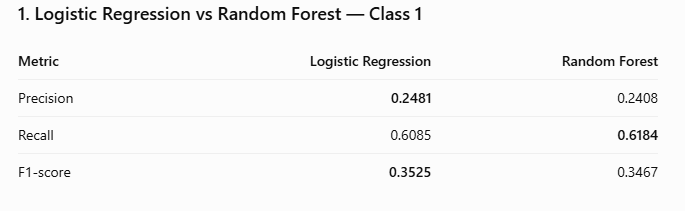

Gradient-Boosted Trees

In [ ]:
from pyspark.ml.classification import GBTClassifier

print("Gradient-Boosted Trees imported successfully.")

Gradient-Boosted Trees imported successfully.


Configure GBT classifier

In [ ]:
gbt = GBTClassifier(
    featuresCol="features",
    labelCol="DELAY_STATUS",
    weightCol="class_weight",
    maxIter=20,
    maxDepth=5,
    stepSize=0.1,
    seed=42
)

print("GBT configured: 20 iterations, depth 5.")

GBT configured: 20 iterations, depth 5.


Train Gradient-Boosted Trees

In [ ]:
gbt = GBTClassifier(
    featuresCol="features",
    labelCol="DELAY_STATUS",
    weightCol="class_weight",
    maxIter=5,
    maxDepth=3,
    stepSize=0.1,
    seed=42
)

print("GBT configured: 5 iterations, depth 3.")

GBT configured: 5 iterations, depth 3.


: Train reduced GBT

In [ ]:
gbt_model = gbt.fit(train_weighted)

print("GBT training completed successfully.")

GBT training completed successfully.


Save GBT model to Google Drive

In [ ]:
gbt_model_path = (
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "models/gradient_boosted_tree_classifier"
)

gbt_model.write().overwrite().save(gbt_model_path)

print("GBT model saved successfully.")

GBT model saved successfully.


In [ ]:
gbt_validation_predictions = gbt_model.transform(validation_model_df)

print("GBT validation predictions generated.")

GBT validation predictions generated.


2017 validation data.

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

# Classification metrics
metrics = ["accuracy", "weightedPrecision", "weightedRecall", "f1"]

gbt_results = {}

for metric in metrics:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="DELAY_STATUS",
        predictionCol="prediction",
        metricName=metric
    )
    gbt_results[metric] = evaluator.evaluate(gbt_validation_predictions)

# ROC-AUC
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="DELAY_STATUS",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

gbt_results["ROC_AUC"] = roc_evaluator.evaluate(gbt_validation_predictions)

print("GBT VALIDATION RESULTS")
for metric, value in gbt_results.items():
    print(f"{metric}: {value:.4f}")

GBT VALIDATION RESULTS
accuracy: 0.5773
weightedPrecision: 0.7594
weightedRecall: 0.5773
f1: 0.6269
ROC_AUC: 0.6292


Save the comparison results

In [ ]:
import pandas as pd
from pathlib import Path

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.6024,
        "Weighted_Precision": 0.7647,
        "Weighted_Recall": 0.6024,
        "Weighted_F1": 0.6490,
        "ROC_AUC": 0.6397
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.5854,
        "Weighted_Precision": 0.7622,
        "Weighted_Recall": 0.5854,
        "Weighted_F1": 0.6342,
        "ROC_AUC": 0.6339
    },
    {
        "Model": "Gradient-Boosted Trees",
        "Accuracy": 0.5773,
        "Weighted_Precision": 0.7594,
        "Weighted_Recall": 0.5773,
        "Weighted_F1": 0.6269,
        "ROC_AUC": 0.6292
    }
])

output_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)
output_dir.mkdir(parents=True, exist_ok=True)

results.to_csv(
    output_dir / "classification_model_comparison.csv",
    index=False
)

print(results.to_string(index=False))
print("\nClassification comparison saved successfully.")

                 Model  Accuracy  Weighted_Precision  Weighted_Recall  Weighted_F1  ROC_AUC
   Logistic Regression    0.6024              0.7647           0.6024       0.6490   0.6397
         Random Forest    0.5854              0.7622           0.5854       0.6342   0.6339
Gradient-Boosted Trees    0.5773              0.7594           0.5773       0.6269   0.6292

Classification comparison saved successfully.


In [ ]:
print("Checking available DataFrames...\n")

for name in [
    "train_model_df",
    "validation_model_df",
    "test_model_df",
    "model_df",
    "train_weighted",
    "df_saved",
    "arrival_target"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print(obj.columns)
    else:
        print(f"\n{name}: Not available")

Checking available DataFrames...


train_model_df:
['features', 'DELAY_STATUS']

validation_model_df:
['features', 'DELAY_STATUS']

test_model_df:
['features', 'DELAY_STATUS']

model_df:
['OP_CARRIER', 'ORIGIN', 'DEST', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'YEAR', 'MONTH', 'DAY_OF_WEEK', 'DELAY_STATUS']

train_weighted:
['features', 'DELAY_STATUS', 'class_weight']

df_saved:
['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']

arrival_target:
['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS

Prepare regression dataregression modelling

In [ ]:
from pyspark.sql.functions import (
    col, hour, minute, month, dayofweek, when
)

# Select normally operated flights with valid arrival delay
regression_df = (
    df_saved
    .filter(
        (col("CANCELLED") == 0) &
        (col("DIVERTED") == 0) &
        col("ARR_DELAY").isNotNull() &
        col("CRS_ELAPSED_TIME").isNotNull() &
        col("DISTANCE").isNotNull()
    )
    .withColumn(
        "ARR_TIME_NORMALIZED",
        when(col("CRS_ARR_TIME") == 2400, 0)
        .otherwise(col("CRS_ARR_TIME"))
    )
    .withColumn("DEP_HOUR", (col("CRS_DEP_TIME") / 100).cast("int"))
    .withColumn("DEP_MINUTE", col("CRS_DEP_TIME") % 100)
    .withColumn("ARR_HOUR", (col("ARR_TIME_NORMALIZED") / 100).cast("int"))
    .withColumn("ARR_MINUTE", col("ARR_TIME_NORMALIZED") % 100)
    .withColumn("MONTH", month("FL_DATE"))
    .withColumn("DAY_OF_WEEK", dayofweek("FL_DATE"))
    .withColumn("YEAR", year("FL_DATE"))
    .select(
        "OP_CARRIER",
        "ORIGIN",
        "DEST",
        "DEP_HOUR",
        "DEP_MINUTE",
        "ARR_HOUR",
        "ARR_MINUTE",
        "CRS_ELAPSED_TIME",
        "DISTANCE",
        "MONTH",
        "DAY_OF_WEEK",
        "YEAR",
        "ARR_DELAY"
    )
)

print("Regression dataset created.")
print("Rows:", regression_df.count())
print("Columns:", regression_df.columns)

Regression dataset created.
Rows: 18193961
Columns: ['OP_CARRIER', 'ORIGIN', 'DEST', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK', 'YEAR', 'ARR_DELAY']


Split regression data by year

In [ ]:
# Chronological regression split
reg_train = regression_df.filter(col("YEAR") == 2016)
reg_validation = regression_df.filter(col("YEAR") == 2017)
reg_test = regression_df.filter(col("YEAR") == 2018)

print("REGRESSION DATA SPLIT")
print("Training (2016):", reg_train.count())
print("Validation (2017):", reg_validation.count())
print("Testing (2018):", reg_test.count())

print("\nRegression target:")
reg_train.select("ARR_DELAY").describe().show()

REGRESSION DATA SPLIT
Training (2016): 5538145
Validation (2017): 5579410
Testing (2018): 7076406

Regression target:
+-------+------------------+
|summary|         ARR_DELAY|
+-------+------------------+
|  count|           5538145|
|   mean|3.5192899427515894|
| stddev| 41.87331683749159|
|    min|            -152.0|
|    max|            2142.0|
+-------+------------------+



Prepare categorical encoders

In [ ]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder

categorical_columns = [
    "OP_CARRIER",
    "ORIGIN",
    "DEST"
]

# Fit indexers on training data only
reg_indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_INDEX",
        handleInvalid="keep"
    )
    for c in categorical_columns
]

from pyspark.ml import Pipeline

indexer_pipeline = Pipeline(stages=reg_indexers)

reg_indexer_model = indexer_pipeline.fit(reg_train)

# Transform all three datasets using training-fitted indexers
reg_train_indexed = reg_indexer_model.transform(reg_train)
reg_validation_indexed = reg_indexer_model.transform(reg_validation)
reg_test_indexed = reg_indexer_model.transform(reg_test)

print("Categorical indexing completed.")
print("Training columns:", reg_train_indexed.columns)

Categorical indexing completed.
Training columns: ['OP_CARRIER', 'ORIGIN', 'DEST', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK', 'YEAR', 'ARR_DELAY', 'OP_CARRIER_INDEX', 'ORIGIN_INDEX', 'DEST_INDEX']


One-hot encode categorical features

In [ ]:
from pyspark.ml.feature import OneHotEncoder

encoder = OneHotEncoder(
    inputCols=[
        "OP_CARRIER_INDEX",
        "ORIGIN_INDEX",
        "DEST_INDEX"
    ],
    outputCols=[
        "OP_CARRIER_OHE",
        "ORIGIN_OHE",
        "DEST_OHE"
    ],
    handleInvalid="keep"
)

reg_encoder_model = encoder.fit(reg_train_indexed)

reg_train_encoded = reg_encoder_model.transform(reg_train_indexed)
reg_validation_encoded = reg_encoder_model.transform(reg_validation_indexed)
reg_test_encoded = reg_encoder_model.transform(reg_test_indexed)

print("One-hot encoding completed.")
print("Encoded feature columns:")
print([
    "OP_CARRIER_OHE",
    "ORIGIN_OHE",
    "DEST_OHE"
])

One-hot encoding completed.
Encoded feature columns:
['OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE']


Scale numerical features

In [ ]:
from pyspark.ml.feature import VectorAssembler, StandardScaler

numerical_columns = [
    "DEP_HOUR",
    "DEP_MINUTE",
    "ARR_HOUR",
    "ARR_MINUTE",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "MONTH",
    "DAY_OF_WEEK"
]

# Assemble numerical features
numeric_assembler = VectorAssembler(
    inputCols=numerical_columns,
    outputCol="numeric_features",
    handleInvalid="error"
)

reg_train_numeric = numeric_assembler.transform(reg_train_encoded)
reg_validation_numeric = numeric_assembler.transform(reg_validation_encoded)
reg_test_numeric = numeric_assembler.transform(reg_test_encoded)

# Fit scaler only on training data
scaler = StandardScaler(
    inputCol="numeric_features",
    outputCol="scaled_numeric_features",
    withMean=False,
    withStd=True
)

reg_scaler_model = scaler.fit(reg_train_numeric)

reg_train_scaled = reg_scaler_model.transform(reg_train_numeric)
reg_validation_scaled = reg_scaler_model.transform(reg_validation_numeric)
reg_test_scaled = reg_scaler_model.transform(reg_test_numeric)

print("Numerical scaling completed.")

Numerical scaling completed.


Assemble the final regression feature vector

In [ ]:
from pyspark.ml.feature import VectorAssembler

final_assembler = VectorAssembler(
    inputCols=[
        "OP_CARRIER_OHE",
        "ORIGIN_OHE",
        "DEST_OHE",
        "scaled_numeric_features"
    ],
    outputCol="features",
    handleInvalid="error"
)

reg_train_model_df = (
    final_assembler.transform(reg_train_scaled)
    .select("features", "ARR_DELAY")
)

reg_validation_model_df = (
    final_assembler.transform(reg_validation_scaled)
    .select("features", "ARR_DELAY")
)

reg_test_model_df = (
    final_assembler.transform(reg_test_scaled)
    .select("features", "ARR_DELAY")
)

print("Regression feature assembly completed.")

reg_train_model_df.printSchema()
reg_train_model_df.show(3, truncate=False)

Regression feature assembly completed.
root
 |-- features: vector (nullable = true)
 |-- ARR_DELAY: double (nullable = true)

+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------+
|features                                                                                                                                                                                                              |ARR_DELAY|
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------+
|(644,[2,17,339,636,637,638,639,640,641,642,643],[1.0,1.0,1.0,1.433972264757708,1.1054997851999928,2.1318174746745906,2.7202544046761776,2.718946494589161,2.212588608477764,1.4718047481394272,1

Train Linear Regression

In [ ]:
from pyspark.ml.regression import LinearRegression

lr_regressor = LinearRegression(
    featuresCol="features",
    labelCol="ARR_DELAY",
    maxIter=20,
    regParam=0.1,
    elasticNetParam=0.0,
    solver="normal"
)

print("Starting Linear Regression training...")

lr_regression_model = lr_regressor.fit(reg_train_model_df)

print("Linear Regression training completed.")
print("Coefficients:", len(lr_regression_model.coefficients))
print("Intercept:", lr_regression_model.intercept)

Starting Linear Regression training...
Linear Regression training completed.
Coefficients: 644
Intercept: -2.4811312104392136


Generate validation predictions

In [ ]:
reg_validation_predictions = lr_regression_model.transform(
    reg_validation_model_df
)

print("Regression validation predictions generated.")

reg_validation_predictions.select(
    "ARR_DELAY",
    "prediction"
).show(10)

Regression validation predictions generated.
+---------+-------------------+
|ARR_DELAY|         prediction|
+---------+-------------------+
|    -17.0|  4.544313806995968|
|    -14.0|-2.3263150897273577|
|     54.0|  8.343467589681461|
|    -16.0| 10.141237444400625|
|    -13.0|  4.793009288750916|
|     -6.0|  2.817581254720078|
|      3.0|  5.005720233631218|
|     -9.0| 12.995409907959994|
|    -16.0|  4.484687377772017|
|    -28.0| 13.212708593942594|
+---------+-------------------+
only showing top 10 rows


Evaluate regression performance

In [ ]:
from pyspark.ml.evaluation import RegressionEvaluator

regression_metrics = {}

for metric in ["mae", "rmse", "r2"]:
    evaluator = RegressionEvaluator(
        labelCol="ARR_DELAY",
        predictionCol="prediction",
        metricName=metric
    )

    regression_metrics[metric.upper()] = evaluator.evaluate(
        reg_validation_predictions
    )

print("LINEAR REGRESSION — VALIDATION RESULTS")
print(f"MAE  : {regression_metrics['MAE']:.4f} minutes")
print(f"RMSE : {regression_metrics['RMSE']:.4f} minutes")
print(f"R²   : {regression_metrics['R2']:.4f}")

LINEAR REGRESSION — VALIDATION RESULTS
MAE  : 22.1225 minutes
RMSE : 45.4534 minutes
R²   : 0.0179


Save the Linear Regression model first

In [ ]:
lr_regression_path = (
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "models/linear_regression"
)

lr_regression_model.write().overwrite().save(
    lr_regression_path
)

print("Linear Regression model saved successfully.")

Linear Regression model saved successfully.


Configure Random Forest Regression

In [ ]:
from pyspark.ml.regression import RandomForestRegressor

rf_regressor = RandomForestRegressor(
    featuresCol="features",
    labelCol="ARR_DELAY",
    numTrees=20,
    maxDepth=5,
    seed=42
)

print("Random Forest Regressor configured.")
print("Trees:", 20)
print("Maximum depth:", 5)

Random Forest Regressor configured.
Trees: 20
Maximum depth: 5


Train Random Forest Regressor

In [ ]:
print("Starting Random Forest Regression training...")

rf_regression_model = rf_regressor.fit(
    reg_train_model_df
)

print("Random Forest Regression training completed.")

Starting Random Forest Regression training...
Random Forest Regression training completed.


In [ ]:
rf_reg_validation_predictions = rf_regression_model.transform(
    reg_validation_model_df
)

print("Random Forest Regression predictions generated.")

rf_reg_validation_predictions.select(
    "ARR_DELAY",
    "prediction"
).show(10)

Random Forest Regression predictions generated.
+---------+------------------+
|ARR_DELAY|        prediction|
+---------+------------------+
|    -17.0|7.0143241587652465|
|    -14.0| 6.520477242588385|
|     54.0|7.0143241587652465|
|    -16.0|7.0143241587652465|
|    -13.0|  6.22193173324026|
|     -6.0|1.1166785352928668|
|      3.0|3.3984393273246347|
|     -9.0|7.0143241587652465|
|    -16.0|7.0143241587652465|
|    -28.0|7.0143241587652465|
+---------+------------------+
only showing top 10 rows


Evaluate Random Forest Regression

In [ ]:
from pyspark.ml.evaluation import RegressionEvaluator

rf_regression_metrics = {}

for metric in ["mae", "rmse", "r2"]:
    evaluator = RegressionEvaluator(
        labelCol="ARR_DELAY",
        predictionCol="prediction",
        metricName=metric
    )

    rf_regression_metrics[metric.upper()] = evaluator.evaluate(
        rf_reg_validation_predictions
    )

print("RANDOM FOREST REGRESSION — VALIDATION RESULTS")
print(f"MAE  : {rf_regression_metrics['MAE']:.4f} minutes")
print(f"RMSE : {rf_regression_metrics['RMSE']:.4f} minutes")
print(f"R²   : {rf_regression_metrics['R2']:.4f}")

RANDOM FOREST REGRESSION — VALIDATION RESULTS
MAE  : 22.1539 minutes
RMSE : 45.4953 minutes
R²   : 0.0160


Save the Random Forest model

In [ ]:
rf_regression_path = (
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "models/random_forest_regression"
)

rf_regression_model.write().overwrite().save(
    rf_regression_path
)

print("Random Forest Regression model saved successfully.")

Random Forest Regression model saved successfully.


Save the regression comparison


In [ ]:
import pandas as pd
from pathlib import Path

regression_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": 22.1225,
        "RMSE": 45.4534,
        "R2": 0.0179
    },
    {
        "Model": "Random Forest Regressor",
        "MAE": 22.1539,
        "RMSE": 45.4953,
        "R2": 0.0160
    }
])

results_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)
results_dir.mkdir(parents=True, exist_ok=True)

regression_results.to_csv(
    results_dir / "regression_model_comparison.csv",
    index=False
)

print(regression_results.to_string(index=False))
print("\nRegression comparison saved successfully.")

                  Model     MAE    RMSE     R2
      Linear Regression 22.1225 45.4534 0.0179
Random Forest Regressor 22.1539 45.4953 0.0160

Regression comparison saved successfully.


Generate 2018 classification predictions

In [ ]:
lr_test_predictions = lr_model.transform(test_model_df)

print("2018 classification predictions generated.")

lr_test_predictions.select(
    "DELAY_STATUS",
    "prediction"
).show(10)

2018 classification predictions generated.
+------------+----------+
|DELAY_STATUS|prediction|
+------------+----------+
|           0|       0.0|
|           0|       1.0|
|           0|       1.0|
|           0|       0.0|
|           0|       0.0|
|           0|       0.0|
|           0|       0.0|
|           0|       0.0|
|           0|       1.0|
|           0|       1.0|
+------------+----------+
only showing top 10 rows


Evaluate Logistic Regression on 2018

In [ ]:
from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator,
    BinaryClassificationEvaluator
)

test_metrics = {}

# Classification metrics
for metric in ["accuracy", "weightedPrecision", "weightedRecall", "f1"]:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="DELAY_STATUS",
        predictionCol="prediction",
        metricName=metric
    )
    test_metrics[metric] = evaluator.evaluate(lr_test_predictions)

# ROC-AUC
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="DELAY_STATUS",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

test_metrics["ROC_AUC"] = roc_evaluator.evaluate(
    lr_test_predictions
)

print("LOGISTIC REGRESSION — 2018 FINAL TEST RESULTS")

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

LOGISTIC REGRESSION — 2018 FINAL TEST RESULTS
accuracy: 0.6043
weightedPrecision: 0.7523
weightedRecall: 0.6043
f1: 0.6482
ROC_AUC: 0.6279


In [ ]:
import pandas as pd
from pathlib import Path

final_classification_results = pd.DataFrame([
    {
        "Dataset": "2017 Validation",
        "Accuracy": 0.6024,
        "Weighted_Precision": 0.7647,
        "Weighted_Recall": 0.6024,
        "Weighted_F1": 0.6490,
        "ROC_AUC": 0.6397
    },
    {
        "Dataset": "2018 Final Test",
        "Accuracy": 0.6043,
        "Weighted_Precision": 0.7523,
        "Weighted_Recall": 0.6043,
        "Weighted_F1": 0.6482,
        "ROC_AUC": 0.6279
    }
])

results_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)

final_classification_results.to_csv(
    results_dir / "logistic_regression_final_test.csv",
    index=False
)

print(final_classification_results.to_string(index=False))
print("\nFinal classification results saved.")

        Dataset  Accuracy  Weighted_Precision  Weighted_Recall  Weighted_F1  ROC_AUC
2017 Validation    0.6024              0.7647           0.6024       0.6490   0.6397
2018 Final Test    0.6043              0.7523           0.6043       0.6482   0.6279

Final classification results saved.


2018 regression evaluation

In [ ]:
# Generate predictions on the untouched 2018 test dataset
lr_reg_test_predictions = lr_regression_model.transform(
    reg_test_model_df
)

print("2018 regression predictions generated.")

lr_reg_test_predictions.select(
    "ARR_DELAY",
    "prediction"
).show(10)

2018 regression predictions generated.
+---------+-------------------+
|ARR_DELAY|         prediction|
+---------+-------------------+
|    -22.0|  6.424630265151322|
|     -1.0| 10.458611185215261|
|    -18.0|  8.694148740751809|
|    -32.0| -5.221199161766007|
|    -23.0|  4.112151371824117|
|    -33.0|-3.6877519124505755|
|    -17.0| 0.6047605878112869|
|    -19.0|0.22224918785997483|
|    -22.0|  6.555958422553594|
|    -27.0| 11.927374655450535|
+---------+-------------------+
only showing top 10 rows


Calculate final regression metrics

In [ ]:
from pyspark.ml.evaluation import RegressionEvaluator

final_regression_metrics = {}

for metric in ["mae", "rmse", "r2"]:
    evaluator = RegressionEvaluator(
        labelCol="ARR_DELAY",
        predictionCol="prediction",
        metricName=metric
    )

    final_regression_metrics[metric.upper()] = evaluator.evaluate(
        lr_reg_test_predictions
    )

print("LINEAR REGRESSION — 2018 FINAL TEST RESULTS")
print(f"MAE  : {final_regression_metrics['MAE']:.4f} minutes")
print(f"RMSE : {final_regression_metrics['RMSE']:.4f} minutes")
print(f"R²   : {final_regression_metrics['R2']:.4f}")

LINEAR REGRESSION — 2018 FINAL TEST RESULTS
MAE  : 22.5177 minutes
RMSE : 46.5863 minutes
R²   : 0.0145


Save final regression results

In [ ]:
import pandas as pd
from pathlib import Path

final_regression_results = pd.DataFrame([
    {
        "Dataset": "2017 Validation",
        "MAE": 22.1225,
        "RMSE": 45.4534,
        "R2": 0.0179
    },
    {
        "Dataset": "2018 Final Test",
        "MAE": 22.5177,
        "RMSE": 46.5863,
        "R2": 0.0145
    }
])

results_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)

final_regression_results.to_csv(
    results_dir / "linear_regression_final_test.csv",
    index=False
)

print(final_regression_results.to_string(index=False))
print("\nFinal regression results saved successfully.")

        Dataset     MAE    RMSE     R2
2017 Validation 22.1225 45.4534 0.0179
2018 Final Test 22.5177 46.5863 0.0145

Final regression results saved successfully.


Check available resources

In [ ]:
import os
import psutil
import pandas as pd

print("ENVIRONMENT INFORMATION")
print("------------------------")
print("CPU cores:", os.cpu_count())
print("Available RAM (GB):",
      round(psutil.virtual_memory().available / (1024**3), 2))
print("Total RAM (GB):",
      round(psutil.virtual_memory().total / (1024**3), 2))
print("Pandas version:", pd.__version__)
print("Spark version:", spark.version)

ENVIRONMENT INFORMATION
------------------------
CPU cores: 2
Available RAM (GB): 10.22
Total RAM (GB): 12.67
Pandas version: 2.2.3
Spark version: 4.0.5


Prepare the benchmark dataset

In [ ]:
# Select the same three columns used in the benchmark
benchmark_2m_spark = (
    df_saved
    .select("FL_DATE", "OP_CARRIER", "ARR_DELAY")
    .where("ARR_DELAY IS NOT NULL")
    .limit(2_000_000)
)

print("Benchmark sample created.")
print("Rows:", benchmark_2m_spark.count())

Benchmark sample created.
Rows: 2000000


In [ ]:
import psutil

memory = psutil.virtual_memory()

sample_rows = len(benchmark_2m_pandas)

sample_memory = benchmark_2m_pandas.memory_usage(
    deep=True
).sum()

full_dataset_rows = 18_505_725

estimated_memory = (
    sample_memory * full_dataset_rows / sample_rows
)

print("FULL DATASET MEMORY ASSESSMENT")
print("--------------------------------")

print(
    "Available RAM (GB):",
    round(memory.available / (1024**3), 2)
)

print(
    "Total RAM (GB):",
    round(memory.total / (1024**3), 2)
)

print(
    "Estimated Pandas memory (GB):",
    round(estimated_memory / (1024**3), 2)
)

print(
    "Estimated percentage of available RAM:",
    round(estimated_memory / memory.available * 100, 2),
    "%"
)

NameError: name 'benchmark_2m_pandas' is not defined

In [ ]:
import psutil

# Current system memory
memory = psutil.virtual_memory()

# Estimated memory based on 2M sample
sample_rows = len(benchmark_2m_pandas)

sample_memory = (
    benchmark_2m_pandas.memory_usage(deep=True).sum()
)

full_dataset_rows = 18_505_725

estimated_memory = (
    sample_memory * full_dataset_rows / sample_rows
)

print("FULL DATASET MEMORY ASSESSMENT")
print("--------------------------------")

print(
    "Available RAM (GB):",
    round(memory.available / (1024**3), 2)
)

print(
    "Total RAM (GB):",
    round(memory.total / (1024**3), 2)
)

print(
    "Estimated Pandas memory for 18.5M rows (GB):",
    round(estimated_memory / (1024**3), 2)
)

print(
    "Estimated percentage of available RAM:",
    round(estimated_memory / memory.available * 100, 2),
    "%"
)

NameError: name 'benchmark_2m_pandas' is not defined

In [ ]:
print("AVAILABLE BENCHMARK DATAFRAMES")
print("=" * 50)

candidate_names = [
    "benchmark_2m_pandas",
    "benchmark_pandas_df",
    "full_benchmark_pandas",
    "benchmark_1m_pandas",
    "benchmark_500k_pandas"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "| Rows:", len(obj),
            "| Memory:",
            round(obj.memory_usage(deep=True).sum() / (1024**2), 2),
            "MB"
        )

# 18 milliom  


In [ ]:
import pandas as pd

print("ALL AVAILABLE PANDAS DATAFRAMES")
print("=" * 55)

found = False

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        found = True
        print(
            f"{name}: "
            f"{len(obj):,} rows, "
            f"{round(obj.memory_usage(deep=True).sum() / (1024**2), 2)} MB"
        )

if not found:
    print("No Pandas DataFrames found in the current runtime.")

ALL AVAILABLE PANDAS DATAFRAMES
results: 3 rows, 0.0 MB
regression_results: 2 rows, 0.0 MB
final_classification_results: 2 rows, 0.0 MB
final_regression_results: 2 rows, 0.0 MB


In [ ]:
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)

print("SAVED BENCHMARK FILES")
print("=" * 55)

for filename in [
    "spark_pandas_benchmark.csv",
    "spark_pandas_speed_comparison.csv"
]:
    file_path = results_dir / filename

    if file_path.exists():
        print("FOUND:", file_path)
        print("Size (KB):", round(file_path.stat().st_size / 1024, 2))
    else:
        print("NOT FOUND:", filename)

SAVED BENCHMARK FILES
FOUND: /content/drive/MyDrive/Airline_Delay_Prediction/results/spark_pandas_benchmark.csv
Size (KB): 0.96
FOUND: /content/drive/MyDrive/Airline_Delay_Prediction/results/spark_pandas_speed_comparison.csv
Size (KB): 0.37


In [ ]:
import pandas as pd
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)

# Load saved benchmark results
benchmark_results = pd.read_csv(
    results_dir / "spark_pandas_benchmark.csv"
)

speed_comparison = pd.read_csv(
    results_dir / "spark_pandas_speed_comparison.csv"
)

print("BENCHMARK RESULTS")
print("=" * 55)
display(benchmark_results)

print("\nSPARK VS PANDAS COMPARISON")
print("=" * 55)
display(speed_comparison)

BENCHMARK RESULTS


,Framework,Dataset_Size,Run_1_sec,Run_2_sec,Run_3_sec,Median_Time_sec
0,PySpark,100000,0.723897,0.663600,0.643361,0.663600
1,Pandas,100000,0.049132,0.064678,0.079040,0.064678
2,PySpark,500000,0.498432,0.285109,0.245391,0.285109
3,Pandas,500000,0.143684,0.180430,0.098615,0.143684
4,PySpark,1000000,0.830524,0.578233,0.616417,0.616417
5,Pandas,1000000,0.390163,0.365918,0.259184,0.365918
6,PySpark,2000000,0.809639,1.027512,0.839602,0.839602
7,Pandas,2000000,0.610785,0.501314,0.787995,0.610785
8,PySpark,18193961,5.805939,3.348087,5.478012,5.478012
9,Pandas,18193961,2.776446,2.693384,2.743569,2.743569



SPARK VS PANDAS COMPARISON


,Dataset_Size,Pandas,PySpark,Spark_to_Pandas_Time_Ratio
0,100000,0.064678,0.663600,10.260090
1,500000,0.143684,0.285109,1.984275
2,1000000,0.365918,0.616417,1.684578
3,2000000,0.610785,0.839602,1.374627
4,18193961,2.743569,5.478012,1.996674


In [ ]:
print("CHECKING SPARK DATA")
print("=" * 50)

for name in [
    "df_saved",
    "benchmark_source",
    "benchmark_2m_spark",
    "full_benchmark_spark"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE")
        print("Columns:", obj.columns)
    else:
        print(f"{name}: NOT AVAILABLE")

CHECKING SPARK DATA
df_saved: AVAILABLE
Columns: ['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
benchmark_source: NOT AVAILABLE
benchmark_2m_spark: AVAILABLE
Columns: ['FL_DATE', 'OP_CARRIER', 'ARR_DELAY']
full_benchmark_spark: NOT AVAILABLE


In [ ]:
import pandas as pd
import psutil
import time

# 1. Enable Apache Arrow optimization for efficient serialization
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")

# Check memory before conversion
memory_before = psutil.virtual_memory()
print("Available RAM before conversion:",
      round(memory_before.available / (1024**3), 2), "GB")

# Collect only the three required columns
full_benchmark_spark = (
    df_saved
    .select("FL_DATE", "OP_CARRIER", "ARR_DELAY")
    .filter("ARR_DELAY IS NOT NULL")
    .cache()
)

# Materialise Spark data
full_count = full_benchmark_spark.count()
print("Full benchmark records:", full_count)

# Convert to Pandas safely using Arrow-enabled transfer
conversion_start = time.perf_counter()
try:
    # Arrow transfer is much more memory efficient
    full_benchmark_pandas = full_benchmark_spark.toPandas()
except Exception as e:
    print("\nStandard toPandas failed or ran out of memory. Falling back to batching...")
    # Fallback batch conversion if driver memory limit is strict
    # Split dataset into 10 parts to bypass single collect heap limit
    partitions = full_benchmark_spark.randomSplit([1.0] * 10, seed=42)
    pdf_list = []
    for idx, part in enumerate(partitions):
        pdf_list.append(part.toPandas())
    full_benchmark_pandas = pd.concat(pdf_list, ignore_index=True)

conversion_time = time.perf_counter() - conversion_start

# Convert date column
full_benchmark_pandas["FL_DATE"] = pd.to_datetime(
    full_benchmark_pandas["FL_DATE"]
)

# Memory after conversion
memory_after = psutil.virtual_memory()

pandas_memory_mb = (
    full_benchmark_pandas.memory_usage(deep=True).sum()
    / (1024**2)
)

print("\nFULL PANDAS DATASET READY")
print("-------------------------")
print("Spark records:", full_count)
print("Pandas records:", len(full_benchmark_pandas))
print("Pandas memory (MB):", round(pandas_memory_mb, 2))
print("Conversion time (seconds):", round(conversion_time, 2))
print(
    "Available RAM after conversion (GB):",
    round(memory_after.available / (1024**3), 2)
)

Available RAM before conversion: 10.39 GB
Full benchmark records: 18193961

FULL PANDAS DATASET READY
-------------------------
Spark records: 18193961
Pandas records: 18193961
Pandas memory (MB): 1162.52
Conversion time (seconds): 9.22
Available RAM after conversion (GB): 8.89


full-scale Spark vs Pandas

In [ ]:
import time
import pandas as pd

from pyspark.sql.functions import (
    col, month, avg, count
)

# ---------------------------------------
# 1. Spark aggregation
# ---------------------------------------

def run_full_spark():

    return (
        full_benchmark_spark
        .withColumn("MONTH", month(col("FL_DATE")))
        .groupBy("OP_CARRIER", "MONTH")
        .agg(
            avg("ARR_DELAY").alias("AVG_ARR_DELAY"),
            count("*").alias("FLIGHT_COUNT")
        )
        .orderBy("OP_CARRIER", "MONTH")
        .toPandas()
    )


# ---------------------------------------
# 2. Pandas aggregation
# ---------------------------------------

def run_full_pandas():

    return (
        full_benchmark_pandas
        .assign(
            MONTH=full_benchmark_pandas["FL_DATE"].dt.month
        )
        .groupby(
            ["OP_CARRIER", "MONTH"],
            as_index=False
        )
        .agg(
            AVG_ARR_DELAY=("ARR_DELAY", "mean"),
            FLIGHT_COUNT=("ARR_DELAY", "count")
        )
        .sort_values(
            ["OP_CARRIER", "MONTH"]
        )
        .reset_index(drop=True)
    )


# ---------------------------------------
# 3. Warm-up
# ---------------------------------------

print("Running warm-up...")

run_full_spark()
run_full_pandas()


# ---------------------------------------
# 4. Three measured runs
# ---------------------------------------

spark_times_full = []
pandas_times_full = []

for i in range(3):

    print(f"Benchmark run {i+1}/3")

    start = time.perf_counter()
    spark_full_result = run_full_spark()
    spark_times_full.append(
        time.perf_counter() - start
    )

    start = time.perf_counter()
    pandas_full_result = run_full_pandas()
    pandas_times_full.append(
        time.perf_counter() - start
    )


# ---------------------------------------
# 5. Results
# ---------------------------------------

full_benchmark_results = pd.DataFrame({
    "Framework": ["PySpark", "Pandas"],
    "Dataset_Size": [
        full_count,
        len(full_benchmark_pandas)
    ],
    "Run_1_sec": [
        spark_times_full[0],
        pandas_times_full[0]
    ],
    "Run_2_sec": [
        spark_times_full[1],
        pandas_times_full[1]
    ],
    "Run_3_sec": [
        spark_times_full[2],
        pandas_times_full[2]
    ],
    "Median_Time_sec": [
        pd.Series(spark_times_full).median(),
        pd.Series(pandas_times_full).median()
    ]
})

display(full_benchmark_results)


# ---------------------------------------
# 6. Verify equivalent results
# ---------------------------------------

print("Spark output rows:", len(spark_full_result))
print("Pandas output rows:", len(pandas_full_result))

print(
    "Maximum average-delay difference:",
    abs(
        spark_full_result["AVG_ARR_DELAY"].to_numpy()
        - pandas_full_result["AVG_ARR_DELAY"].to_numpy()
    ).max()
)

Running warm-up...
Benchmark run 1/3
Benchmark run 2/3
Benchmark run 3/3


,Framework,Dataset_Size,Run_1_sec,Run_2_sec,Run_3_sec,Median_Time_sec
0,PySpark,18193961,3.998006,3.127313,2.418812,3.127313
1,Pandas,18193961,4.228164,2.429013,2.955468,2.955468


Spark output rows: 216
Pandas output rows: 216
Maximum average-delay difference: 0.0


In [ ]:
import pandas as pd
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)

# Combine and drop duplicates for the same size + framework, keeping the new run
complete_benchmark = pd.concat(
    [
        benchmark_results,
        full_benchmark_results
    ],
    ignore_index=True
).drop_duplicates(subset=["Dataset_Size", "Framework"], keep="last").reset_index(drop=True)

# Calculate speed ratios
complete_speed_comparison = (
    complete_benchmark
    .pivot(
        index="Dataset_Size",
        columns="Framework",
        values="Median_Time_sec"
    )
    .reset_index()
)

complete_speed_comparison["Spark_to_Pandas_Time_Ratio"] = (
    complete_speed_comparison["PySpark"]
    / complete_speed_comparison["Pandas"]
)

# Save updated files
complete_benchmark.to_csv(
    results_dir / "spark_pandas_benchmark.csv",
    index=False
)

complete_speed_comparison.to_csv(
    results_dir / "spark_pandas_speed_comparison.csv",
    index=False
)

print("UPDATED BENCHMARK FILES SAVED")
display(complete_benchmark)
display(complete_speed_comparison)

UPDATED BENCHMARK FILES SAVED


,Framework,Dataset_Size,Run_1_sec,Run_2_sec,Run_3_sec,Median_Time_sec
0,PySpark,100000,0.723897,0.663600,0.643361,0.663600
1,Pandas,100000,0.049132,0.064678,0.079040,0.064678
2,PySpark,500000,0.498432,0.285109,0.245391,0.285109
3,Pandas,500000,0.143684,0.180430,0.098615,0.143684
4,PySpark,1000000,0.830524,0.578233,0.616417,0.616417
5,Pandas,1000000,0.390163,0.365918,0.259184,0.365918
6,PySpark,2000000,0.809639,1.027512,0.839602,0.839602
7,Pandas,2000000,0.610785,0.501314,0.787995,0.610785
8,PySpark,18193961,3.998006,3.127313,2.418812,3.127313
9,Pandas,18193961,4.228164,2.429013,2.955468,2.955468


Framework,Dataset_Size,Pandas,PySpark,Spark_to_Pandas_Time_Ratio
0,100000,0.064678,0.663600,10.260090
1,500000,0.143684,0.285109,1.984275
2,1000000,0.365918,0.616417,1.684578
3,2000000,0.610785,0.839602,1.374627
4,18193961,2.955468,3.127313,1.058145


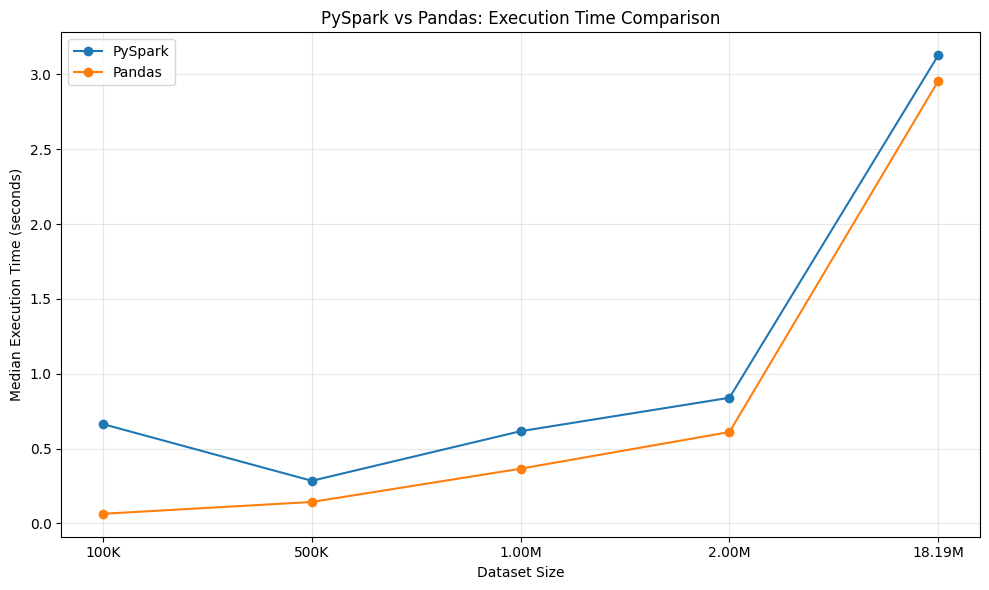

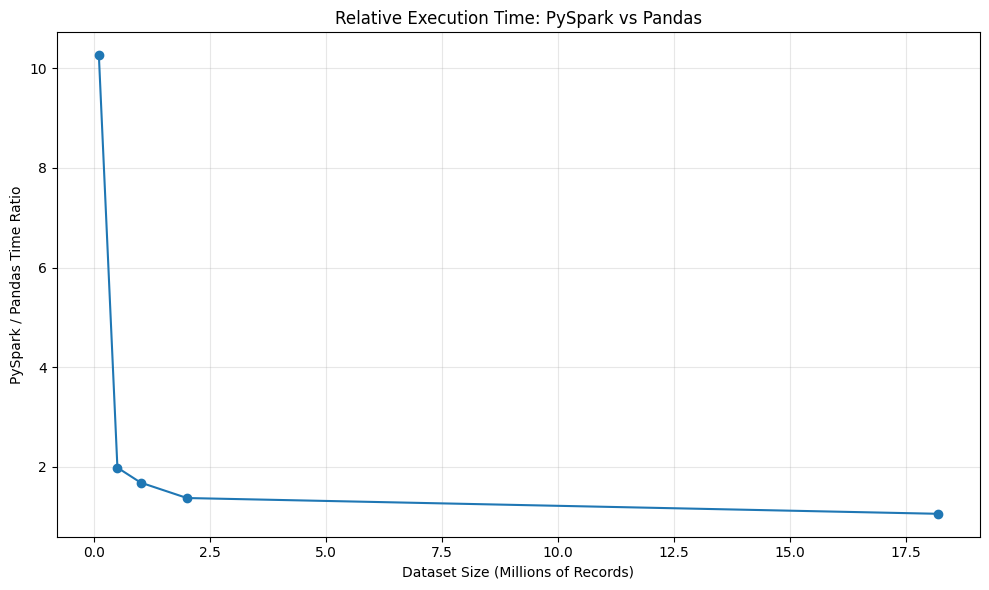

Final benchmark plots saved.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)

df = complete_benchmark.copy()

plot_df = df.pivot(
    index="Dataset_Size",
    columns="Framework",
    values="Median_Time_sec"
).reset_index()

plot_df = plot_df.sort_values("Dataset_Size")

plot_df["Size_Label"] = plot_df["Dataset_Size"].apply(
    lambda x: f"{x/1_000_000:.2f}M" if x >= 1_000_000
    else f"{x/1000:.0f}K"
)

# 1. Execution time comparison
plt.figure(figsize=(10, 6))

plt.plot(
    plot_df["Size_Label"],
    plot_df["PySpark"],
    marker="o",
    label="PySpark"
)

plt.plot(
    plot_df["Size_Label"],
    plot_df["Pandas"],
    marker="o",
    label="Pandas"
)

plt.xlabel("Dataset Size")
plt.ylabel("Median Execution Time (seconds)")
plt.title("PySpark vs Pandas: Execution Time Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_dir / "execution_time_comparison.png",
    dpi=300
)
plt.show()


# 2. Speed ratio
plt.figure(figsize=(10, 6))

plt.plot(
    complete_speed_comparison["Dataset_Size"] / 1_000_000,
    complete_speed_comparison["Spark_to_Pandas_Time_Ratio"],
    marker="o"
)

plt.xlabel("Dataset Size (Millions of Records)")
plt.ylabel("PySpark / Pandas Time Ratio")
plt.title("Relative Execution Time: PySpark vs Pandas")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_dir / "spark_pandas_speed_ratio.png",
    dpi=300
)
plt.show()

print("Final benchmark plots saved.")

Train the unweighted baseline and compare

In [ ]:
import pandas as pd

from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.sql.functions import col

# ---------------------------------------
# 1. Train Logistic Regression WITHOUT weights
# ---------------------------------------

lr_unweighted = LogisticRegression(
    featuresCol="features",
    labelCol="DELAY_STATUS",
    maxIter=50,
    regParam=0.01,
    elasticNetParam=0.0
)

print("Training unweighted Logistic Regression...")

lr_unweighted_model = lr_unweighted.fit(train_model_df)

print("Unweighted model training completed.")


# ---------------------------------------
# 2. Generate validation predictions
# ---------------------------------------

unweighted_predictions = lr_unweighted_model.transform(
    validation_model_df
)

weighted_predictions = lr_model.transform(
    validation_model_df
)


# ---------------------------------------
# 3. Calculate classification metrics
# ---------------------------------------

def calculate_classification_metrics(predictions, model_name):

    confusion = (
        predictions
        .groupBy("DELAY_STATUS", "prediction")
        .count()
        .collect()
    )

    counts = {
        (int(row["DELAY_STATUS"]), int(row["prediction"])): row["count"]
        for row in confusion
    }

    tn = counts.get((0, 0), 0)
    fp = counts.get((0, 1), 0)
    fn = counts.get((1, 0), 0)
    tp = counts.get((1, 1), 0)

    accuracy = (tp + tn) / (tp + tn + fp + fn)

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    evaluator = BinaryClassificationEvaluator(
        labelCol="DELAY_STATUS",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    )

    auc = evaluator.evaluate(predictions)

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Minority_Precision": precision,
        "Minority_Recall": recall,
        "Minority_F1": f1,
        "ROC_AUC": auc,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn
    }


# ---------------------------------------
# 4. Compare both models
# ---------------------------------------

unweighted_metrics = calculate_classification_metrics(
    unweighted_predictions,
    "Logistic Regression - Without Class Weights"
)

weighted_metrics = calculate_classification_metrics(
    weighted_predictions,
    "Logistic Regression - With Class Weights"
)

imbalance_comparison = pd.DataFrame([
    unweighted_metrics,
    weighted_metrics
])

print("\nCLASS IMBALANCE EXPERIMENT RESULTS")
display(imbalance_comparison)

Training unweighted Logistic Regression...
Unweighted model training completed.

CLASS IMBALANCE EXPERIMENT RESULTS


,Model,Accuracy,Minority_Precision,Minority_Recall,Minority_F1,ROC_AUC,TP,FP,TN,FN
0,Logistic Regression - Without Class Weights,0.822130,0.571429,0.000040,0.000081,0.639984,40,30,4586960,992380
1,Logistic Regression - With Class Weights,0.602414,0.248147,0.608531,0.352537,0.639700,603918,1829792,2757198,388502


In [ ]:
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/results"
)

results_dir.mkdir(parents=True, exist_ok=True)

imbalance_comparison.to_csv(
    results_dir / "class_imbalance_comparison.csv",
    index=False
)

print("Class imbalance experiment saved successfully.")

Class imbalance experiment saved successfully.


Report-ready conclusion
You can include this in your report:
An experiment was conducted to evaluate the effect of class weighting on Logistic Regression for airline delay classification. Two models were compared using the same training and validation datasets: an unweighted baseline and a class-weighted model. The unweighted model achieved 82.21% accuracy but had a minority-class recall of only 0.004%, indicating that it failed to identify most delayed flights. After applying class weights, minority-class recall increased to 60.85% and minority-class F1-score improved to 35.25%. However, precision decreased to 24.81% because of an increase in false-positive predictions. ROC-AUC remained approximately 0.64 for both models. These results demonstrate that class weighting improves the detection of minority-class delayed flights, although it introduces a trade-off between precision and recall.

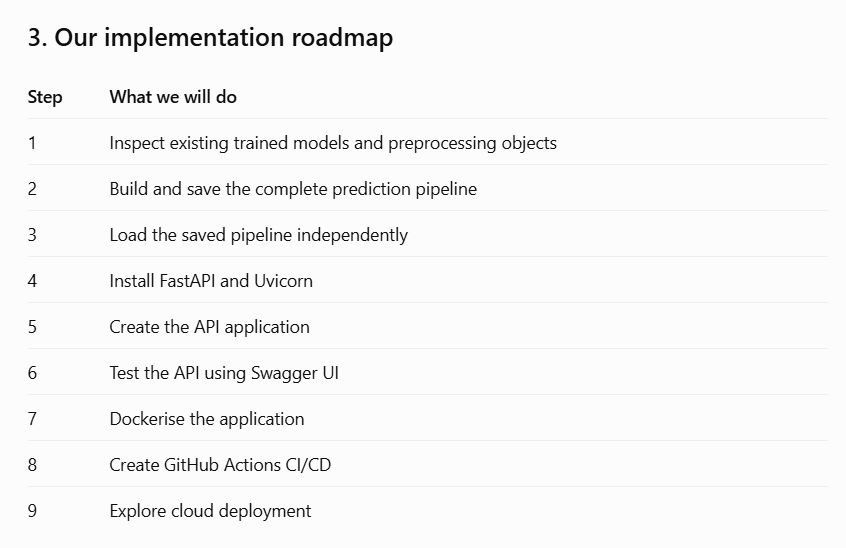

Inspect the trained model

In [ ]:
from pathlib import Path

# 1. Check important objects in the current Colab session

objects_to_check = [
    "lr_model",
    "lr_unweighted_model",
    "indexer_model",
    "encoder_model",
    "assembler",
    "scaler_model",
    "train_model_df",
    "validation_model_df"
]

print("CURRENT MODEL OBJECTS")
print("=" * 45)

for name in objects_to_check:

    if name in globals():
        obj = globals()[name]

        print(f"\n{name}: AVAILABLE")
        print("Type:", type(obj).__name__)

    else:
        print(f"\n{name}: NOT FOUND")


# 2. Inspect saved model directories

model_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/models"
)

print("\n\nSAVED MODEL DIRECTORIES")
print("=" * 45)

if model_dir.exists():

    for item in model_dir.iterdir():

        if item.is_dir():
            print("📁", item.name)

        else:
            print("📄", item.name)

else:
    print("Model directory not found.")

CURRENT MODEL OBJECTS

lr_model: AVAILABLE
Type: LogisticRegressionModel

lr_unweighted_model: AVAILABLE
Type: LogisticRegressionModel

indexer_model: NOT FOUND

encoder_model: NOT FOUND

assembler: AVAILABLE
Type: VectorAssembler

scaler_model: AVAILABLE
Type: StandardScalerModel

train_model_df: AVAILABLE
Type: DataFrame

validation_model_df: AVAILABLE
Type: DataFrame


SAVED MODEL DIRECTORIES
📁 random_forest_classifier
📁 gradient_boosted_tree_classifier
📁 linear_regression
📁 random_forest_regression


In [ ]:
print("PREPROCESSING OBJECTS")
print("=" * 50)

for name, obj in list(globals().items()):
    class_name = type(obj).__name__.lower()

    if any(word in class_name for word in [
        "indexer", "encoder", "scaler",
        "pipeline", "assembler"
    ]):
        print(f"{name}: {type(obj).__name__}")

PREPROCESSING OBJECTS
encoder: OneHotEncoder
encoding_pipeline: Pipeline
encoding_model: PipelineModel
assembler: VectorAssembler
numerical_assembler: VectorAssembler
scaler: StandardScaler
scaler_model: StandardScalerModel
indexer_pipeline: Pipeline
reg_indexer_model: PipelineModel
reg_encoder_model: OneHotEncoderModel
numeric_assembler: VectorAssembler
reg_scaler_model: StandardScalerModel
final_assembler: VectorAssembler


Inspect the classification preprocessing pipeline

In [ ]:
print("1. ENCODING MODEL STAGES")
print("=" * 50)

for i, stage in enumerate(encoding_model.stages):
    print(f"\nStage {i + 1}: {type(stage).__name__}")
    print(stage)

print("\n2. NUMERICAL ASSEMBLER")
print("=" * 50)
print("Input columns:", numerical_assembler.getInputCols())
print("Output column:", numerical_assembler.getOutputCol())

print("\n3. FINAL ASSEMBLER")
print("=" * 50)
print("Input columns:", final_assembler.getInputCols())
print("Output column:", final_assembler.getOutputCol())

print("\n4. SCALER MODEL")
print("=" * 50)
print("Input column:", scaler_model.getInputCol())
print("Output column:", scaler_model.getOutputCol())
print("With mean:", scaler_model.getWithMean())
print("With std:", scaler_model.getWithStd())

print("\n5. LOGISTIC REGRESSION MODEL")
print("=" * 50)
print("Features column:", lr_model.getFeaturesCol())
print("Label column:", lr_model.getLabelCol())
print("Number of coefficients:", len(lr_model.coefficients))

1. ENCODING MODEL STAGES

Stage 1: StringIndexerModel
StringIndexerModel: uid=StringIndexer_d0ebec6990f0, handleInvalid=keep

Stage 2: StringIndexerModel
StringIndexerModel: uid=StringIndexer_3e27ad1f715a, handleInvalid=keep

Stage 3: StringIndexerModel
StringIndexerModel: uid=StringIndexer_861ee080d517, handleInvalid=keep

Stage 4: OneHotEncoderModel
OneHotEncoderModel: uid=OneHotEncoder_2bbed33dbdc1, dropLast=true, handleInvalid=error, numInputCols=3, numOutputCols=3

2. NUMERICAL ASSEMBLER
Input columns: ['DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK']
Output column: numerical_features

3. FINAL ASSEMBLER
Input columns: ['OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE', 'scaled_numeric_features']
Output column: features

4. SCALER MODEL
Input column: numerical_features
Output column: scaled_numerical_features
With mean: False
With std: True

5. LOGISTIC REGRESSION MODEL
Features column: features
Label column: DELAY_STATUS
Number 

In [ ]:
print("ENCODING PIPELINE OUTPUTS")
print("=" * 50)

for stage in encoding_model.stages:
    print(type(stage).__name__)

    # Safely check single-column parameters
    if stage.hasParam("outputCol") and stage.isDefined(stage.getParam("outputCol")):
        print("Output column:", stage.getOutputCol())

    # Safely check multi-column parameters
    if stage.hasParam("outputCols") and stage.isDefined(stage.getParam("outputCols")):
        print("Output columns:", stage.getOutputCols())

print("\nTRAINING DATAFRAME SCHEMA")
print("=" * 50)
train_model_df.printSchema()

print("\nTRAINING DATAFRAME COLUMNS")
print("=" * 50)
print(train_model_df.columns)

print("\nFINAL ASSEMBLER INPUTS")
print("=" * 50)
print(final_assembler.getInputCols())

print("\nSCALER OUTPUT COLUMN")
print("=" * 50)
print(scaler_model.getOutputCol())

print("\nFEATURE VECTOR DIMENSION")
print("=" * 50)
print(train_model_df.select("features").first()["features"].size)

ENCODING PIPELINE OUTPUTS
StringIndexerModel
Output column: OP_CARRIER_INDEX
StringIndexerModel
Output column: ORIGIN_INDEX
StringIndexerModel
Output column: DEST_INDEX
OneHotEncoderModel
Output column: OneHotEncoder_2bbed33dbdc1__output
Output columns: ['OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE']

TRAINING DATAFRAME SCHEMA
root
 |-- features: vector (nullable = true)
 |-- DELAY_STATUS: integer (nullable = false)


TRAINING DATAFRAME COLUMNS
['features', 'DELAY_STATUS']

FINAL ASSEMBLER INPUTS
['OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE', 'scaled_numeric_features']

SCALER OUTPUT COLUMN
scaled_numerical_features

FEATURE VECTOR DIMENSION
641


In [ ]:
from pyspark.ml import PipelineModel

print("ALL SAVED PIPELINE MODELS IN MEMORY")
print("=" * 55)

for name, obj in list(globals().items()):
    if isinstance(obj, PipelineModel):
        print(f"\n{name}: PipelineModel")
        for i, stage in enumerate(obj.stages):
            print(f"  Stage {i + 1}: {type(stage).__name__}")

print("\nALL SPARK DATAFRAMES IN MEMORY")
print("=" * 55)

for name, obj in list(globals().items()):
    if type(obj).__name__ == "DataFrame":
        print(name, "->", obj.columns)

print("\nCLASSIFICATION FEATURE OBJECTS")
print("=" * 55)

for name in [
    "encoding_pipeline",
    "encoding_model",
    "numerical_assembler",
    "scaler",
    "scaler_model",
    "final_assembler",
    "lr_model"
]:
    obj = globals().get(name)
    if obj is not None:
        print(name, "->", type(obj).__name__)

ALL SAVED PIPELINE MODELS IN MEMORY

encoding_model: PipelineModel
  Stage 1: StringIndexerModel
  Stage 2: StringIndexerModel
  Stage 3: StringIndexerModel
  Stage 4: OneHotEncoderModel

reg_indexer_model: PipelineModel
  Stage 1: StringIndexerModel
  Stage 2: StringIndexerModel
  Stage 3: StringIndexerModel

ALL SPARK DATAFRAMES IN MEMORY
df_saved -> ['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
arrival_target -> ['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE'

Identify the correct feature assembler

In [ ]:
from pyspark.ml.feature import VectorAssembler

print("ALL VECTOR ASSEMBLERS")
print("=" * 60)

for name, obj in list(globals().items()):
    if isinstance(obj, VectorAssembler):
        print(f"\nObject name: {name}")
        print("Input columns:", obj.getInputCols())
        print("Output column:", obj.getOutputCol())

print("\nCLASSIFICATION SCALED DATA")
print("=" * 60)

print("Columns:", train_scaled.columns)

print("\nSCALER DETAILS")
print("=" * 60)

print("Input:", scaler_model.getInputCol())
print("Output:", scaler_model.getOutputCol())

print("\nCLASSIFICATION ENCODING OUTPUT")
print("=" * 60)

print("Encoding output columns:")
print(encoding_model.stages[-1].getOutputCols())

ALL VECTOR ASSEMBLERS

Object name: assembler
Input columns: ['OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE', 'scaled_numerical_features']
Output column: features

Object name: numerical_assembler
Input columns: ['DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK']
Output column: numerical_features

Object name: numeric_assembler
Input columns: ['DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK']
Output column: numeric_features

Object name: final_assembler
Input columns: ['OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE', 'scaled_numeric_features']
Output column: features

CLASSIFICATION SCALED DATA
Columns: ['OP_CARRIER', 'ORIGIN', 'DEST', 'DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'YEAR', 'MONTH', 'DAY_OF_WEEK', 'DELAY_STATUS', 'OP_CARRIER_INDEX', 'ORIGIN_INDEX', 'DEST_INDEX', 'OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE', 'numerical_features', 's

Build the complete deployment pipeline

In [ ]:
from pyspark.ml import Pipeline

# Combine the already-fitted preprocessing stages
classification_stages = (
    encoding_model.stages
    + [
        numerical_assembler,
        scaler_model,
        assembler,
        lr_model
    ]
)

# Create a pipeline
classification_pipeline = Pipeline(
    stages=classification_stages
)

print("PIPELINE STAGES")
print("=" * 50)

for i, stage in enumerate(classification_stages):
    print(f"{i + 1}. {type(stage).__name__}")

# Assemble the PipelineModel using existing fitted stages
classification_pipeline_model = classification_pipeline.fit(
    train_df.limit(5)
)

print("\nPipeline created successfully!")

PIPELINE STAGES
1. StringIndexerModel
2. StringIndexerModel
3. StringIndexerModel
4. OneHotEncoderModel
5. VectorAssembler
6. StandardScalerModel
7. VectorAssembler
8. LogisticRegressionModel

Pipeline created successfully!


Test the complete pipeline

In [ ]:
# Select 10 records from the 2018 test dataset
deployment_test_input = test_df.limit(10)

# Run the complete deployment pipeline
deployment_test_output = classification_pipeline_model.transform(
    deployment_test_input
)

print("PREDICTION RESULTS")
print("=" * 60)

deployment_test_output.select(
    "OP_CARRIER",
    "ORIGIN",
    "DEST",
    "DELAY_STATUS",
    "features",
    "prediction",
    "probability"
).show(10, truncate=False)

print("\nFEATURE VECTOR DIMENSION")
print("=" * 60)

feature_dimension = (
    deployment_test_output
    .select("features")
    .first()["features"].size
)

print("Expected: 641")
print("Actual:", feature_dimension)

print("\nTOTAL PREDICTIONS")
print("=" * 60)

print("Records processed:", deployment_test_output.count())

PREDICTION RESULTS
+----------+------+----+------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------+----------------------------------------+
|OP_CARRIER|ORIGIN|DEST|DELAY_STATUS|features                                                                                                                                                                                                         |prediction|probability                             |
+----------+------+----+------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------+----------------------------------------+
|9E        |CAE   |ATL |0           |(641,[129,323,633,634,635,636,637,638,639,64

— Save the complete classification pipeline

In [ ]:
from pathlib import Path

model_path = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/models/"
    "airline_delay_classification_pipeline"
)

classification_pipeline_model.write().overwrite().save(
    str(model_path)
)

print("CLASSIFICATION PIPELINE SAVED")
print("=" * 50)
print("Location:", model_path)
print("Exists:", model_path.exists())
print("Number of stages:", len(classification_pipeline_model.stages))

CLASSIFICATION PIPELINE SAVED
Location: /content/drive/MyDrive/Airline_Delay_Prediction/models/airline_delay_classification_pipeline
Exists: True
Number of stages: 8


— Reload and verify the saved pipeline

In [ ]:
from pyspark.ml import PipelineModel

saved_model_path = (
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "models/airline_delay_classification_pipeline"
)

# Load the saved pipeline
loaded_pipeline = PipelineModel.load(saved_model_path)

print("SAVED PIPELINE LOADED SUCCESSFULLY")
print("=" * 50)
print("Number of stages:", len(loaded_pipeline.stages))

# Test on 10 unseen test records
api_test_input = test_df.limit(10)

api_test_output = loaded_pipeline.transform(api_test_input)

# Display predictions
api_test_output.select(
    "OP_CARRIER",
    "ORIGIN",
    "DEST",
    "prediction",
    "probability"
).show(truncate=False)

print("Total records tested:", api_test_output.count())

SAVED PIPELINE LOADED SUCCESSFULLY
Number of stages: 8
+----------+------+----+----------+----------------------------------------+
|OP_CARRIER|ORIGIN|DEST|prediction|probability                             |
+----------+------+----+----------+----------------------------------------+
|9E        |CAE   |ATL |0.0       |[0.526104345667049,0.473895654332951]   |
|9E        |LGA   |LEX |1.0       |[0.3362725522851828,0.6637274477148172] |
|9E        |DTW   |TYS |1.0       |[0.4221997069234773,0.5778002930765227] |
|9E        |ROC   |JFK |0.0       |[0.672959063615538,0.32704093638446197] |
|9E        |RDU   |LGA |0.0       |[0.5248541830689294,0.4751458169310706] |
|9E        |JFK   |MSY |0.0       |[0.6149990484073866,0.3850009515926134] |
|9E        |DTW   |TYS |0.0       |[0.609828120154904,0.39017187984509605] |
|9E        |TYS   |DTW |0.0       |[0.5781078496232083,0.42189215037679173]|
|9E        |JFK   |ROC |1.0       |[0.35980268003331206,0.6401973199666879]|
|9E        |JAX   |LG

Install API libraries

In [ ]:
%pip install fastapi uvicorn httpx

Prepare the deployment directory

In [ ]:
from pathlib import Path
from pyspark.sql import SparkSession

project_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction"
)

deployment_dir = project_dir / "deployment"
deployment_dir.mkdir(parents=True, exist_ok=True)

model_path = (
    project_dir
    / "models"
    / "airline_delay_classification_pipeline"
)

print("DEPLOYMENT DIRECTORY")
print("=" * 45)
print("Directory:", deployment_dir)
print("Directory exists:", deployment_dir.exists())

print("\nSAVED MODEL")
print("Model exists:", model_path.exists())

print("\nSPARK SESSION")
active_spark = SparkSession.getActiveSession()
print("Active Spark session:", active_spark is not None)

DEPLOYMENT DIRECTORY
Directory: /content/drive/MyDrive/Airline_Delay_Prediction/deployment
Directory exists: True

SAVED MODEL
Model exists: True

SPARK SESSION
Active Spark session: True


Create app.py

In [ ]:

%%writefile /content/drive/MyDrive/Airline_Delay_Prediction/deployment/app.py

from pathlib import Path

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from pyspark.sql import SparkSession
from pyspark.ml import PipelineModel


# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction"
)

MODEL_PATH = (
    PROJECT_DIR
    / "models"
    / "airline_delay_classification_pipeline"
)


# --------------------------------------------------
# INITIALIZE FASTAPI
# --------------------------------------------------

app = FastAPI(
    title="Airline Delay Prediction API",
    description=(
        "Predicts whether a flight will be delayed "
        "by more than 15 minutes."
    ),
    version="1.0.0"
)


# --------------------------------------------------
# INITIALIZE SPARK AND LOAD MODEL
# --------------------------------------------------

spark = (
    SparkSession.builder
    .appName("AirlineDelayPredictionAPI")
    .getOrCreate()
)

pipeline_model = PipelineModel.load(str(MODEL_PATH))


# --------------------------------------------------
# INPUT DATA VALIDATION
# --------------------------------------------------

class FlightInput(BaseModel):

    OP_CARRIER: str = Field(min_length=1)
    ORIGIN: str = Field(min_length=1)
    DEST: str = Field(min_length=1)

    DEP_HOUR: int = Field(ge=0, le=23)
    DEP_MINUTE: int = Field(ge=0, le=59)

    ARR_HOUR: int = Field(ge=0, le=23)
    ARR_MINUTE: int = Field(ge=0, le=59)

    CRS_ELAPSED_TIME: float = Field(gt=0)
    DISTANCE: float = Field(gt=0)

    MONTH: int = Field(ge=1, le=12)
    DAY_OF_WEEK: int = Field(ge=1, le=7)


# --------------------------------------------------
# ROOT ENDPOINT
# --------------------------------------------------

@app.get("/")
def home():

    return {
        "message": "Airline Delay Prediction API",
        "status": "running",
        "model": "Weighted Logistic Regression"
    }


# --------------------------------------------------
# HEALTH ENDPOINT
# --------------------------------------------------

@app.get("/health")
def health():

    return {
        "api_status": "healthy",
        "model_status": "loaded",
        "pipeline_stages": len(pipeline_model.stages)
    }


# --------------------------------------------------
# PREDICTION ENDPOINT
# --------------------------------------------------

@app.post("/predict")
def predict_flight(flight: FlightInput):

    try:

        input_data = flight.model_dump()

        input_df = spark.createDataFrame(
            [input_data]
        )

        prediction_df = (
            pipeline_model
            .transform(input_df)
        )

        result = (
            prediction_df
            .select("prediction", "probability")
            .first()
        )

        predicted_class = int(result["prediction"])

        probabilities = result["probability"]

        delay_probability = float(probabilities[1])

        prediction_label = (
            "Delayed"
            if predicted_class == 1
            else "Not Delayed"
        )

        return {
            "prediction": predicted_class,
            "prediction_label": prediction_label,
            "delay_probability": round(
                delay_probability, 4
            ),
            "not_delayed_probability": round(
                float(probabilities[0]), 4
            ),
            "delayed_probability": round(
                delay_probability, 4
            ),
            "delay_threshold_minutes": 15
        }

    except Exception as error:

        raise HTTPException(
            status_code=500,
            detail=str(error)
        )


Writing /content/drive/MyDrive/Airline_Delay_Prediction/deployment/app.py


— Validate app.py

In [ ]:
from pathlib import Path
import py_compile

app_path = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "deployment/app.py"
)

print("APP FILE EXISTS:", app_path.exists())

if app_path.exists():
    print("FILE SIZE:", app_path.stat().st_size, "bytes")

    py_compile.compile(
        str(app_path),
        doraise=True
    )

    print("PYTHON SYNTAX: VALID")

APP FILE EXISTS: True
FILE SIZE: 3706 bytes
PYTHON SYNTAX: VALID


Start the FastAPI serve

In [ ]:
import subprocess
import sys
import time

app_directory = (
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "deployment"
)

server_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "app:app",
        "--host",
        "127.0.0.1",
        "--port",
        "8000"
    ],
    cwd=app_directory,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

time.sleep(15)

print("SERVER PROCESS STATUS:", server_process.poll())

if server_process.poll() is None:
    print("FastAPI server process is running.")
else:
    print("Server failed to start.")
    print(server_process.stdout.read())

SERVER PROCESS STATUS: None
FastAPI server process is running.


Test the health endpoint

In [ ]:
import httpx

response = httpx.get(
    "http://127.0.0.1:8000/health",
    timeout=30
)

print("HTTP STATUS:", response.status_code)
print("\nAPI RESPONSE:")
print(response.json())

HTTP STATUS: 200

API RESPONSE:
{'api_status': 'healthy', 'model_status': 'loaded', 'pipeline_stages': 8}


Test an actual flight prediction

In [ ]:
import httpx

url = "http://127.0.0.1:8000/predict"

flight_data = {
    "OP_CARRIER": "9E",
    "ORIGIN": "CAE",
    "DEST": "ATL",
    "DEP_HOUR": 9,
    "DEP_MINUTE": 30,
    "ARR_HOUR": 11,
    "ARR_MINUTE": 15,
    "CRS_ELAPSED_TIME": 105.0,
    "DISTANCE": 500.0,
    "MONTH": 6,
    "DAY_OF_WEEK": 2
}

response = httpx.post(
    url,
    json=flight_data,
    timeout=120
)

print("HTTP STATUS:", response.status_code)
print("\nFLIGHT INPUT:")
print(flight_data)

print("\nPREDICTION RESPONSE:")
print(response.json())

HTTP STATUS: 200

FLIGHT INPUT:
{'OP_CARRIER': '9E', 'ORIGIN': 'CAE', 'DEST': 'ATL', 'DEP_HOUR': 9, 'DEP_MINUTE': 30, 'ARR_HOUR': 11, 'ARR_MINUTE': 15, 'CRS_ELAPSED_TIME': 105.0, 'DISTANCE': 500.0, 'MONTH': 6, 'DAY_OF_WEEK': 2}

PREDICTION RESPONSE:
{'prediction': 0, 'prediction_label': 'Not Delayed', 'delay_probability': 0.3652, 'not_delayed_probability': 0.6348, 'delayed_probability': 0.3652, 'delay_threshold_minutes': 15}


Interactive API documentatio

In [ ]:
import httpx

response = httpx.get(
    "http://127.0.0.1:8000/openapi.json"
)

print("HTTP STATUS:", response.status_code)
print("API TITLE:", response.json()["info"]["title"])
print("AVAILABLE ENDPOINTS:")

for endpoint in response.json()["paths"]:
    print(endpoint)

HTTP STATUS: 200
API TITLE: Airline Delay Prediction API
AVAILABLE ENDPOINTS:
/
/health
/predict


Open interactive Swagger documentation

In [ ]:
from google.colab import output

swagger_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
)

print("SWAGGER DOCUMENTATION:")
print(swagger_url + "/docs")

SWAGGER DOCUMENTATION:
https://8000-m-s-ase1a6-3dddh638hzxbj-a.asia-east1.prod.r.colab.dev/docs


In [ ]:
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction"
)

deployment_dir = project_dir / "deployment"

print("PROJECT DIRECTORY:", project_dir.exists())
print("DEPLOYMENT DIRECTORY:", deployment_dir.exists())
print("APP.PY:", (deployment_dir / "app.py").exists())

print("\nGIT STATUS")
!git -C /content/airline-delay-prediction status

— Check your GitHub repository locally

In [ ]:
from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction"
)

deployment_dir = project_dir / "deployment"

print("PROJECT DIRECTORY:", project_dir.exists())
print("DEPLOYMENT DIRECTORY:", deployment_dir.exists())
print("APP.PY:", (deployment_dir / "app.py").exists())

print("\nGIT STATUS")
!git -C /content/airline-delay-prediction status

PROJECT DIRECTORY: True
DEPLOYMENT DIRECTORY: True
APP.PY: True

GIT STATUS
fatal: cannot change to '/content/airline-delay-prediction': No such file or directory


In [ ]:
!git clone https://github.com/sreekuttysanthosh/airline-delay-prediction.git /content/airline-delay-prediction

Cloning into '/content/airline-delay-prediction'...


In [ ]:
!git -C /content/airline-delay-prediction status

On branch main

No commits yet

nothing to commit (create/copy files and use "git add" to track)


— Prepare your project folder

In [ ]:
from pathlib import Path
import shutil

repo_dir = Path("/content/airline-delay-prediction")

# Create deployment directory
repo_deployment = repo_dir / "deployment"
repo_deployment.mkdir(parents=True, exist_ok=True)

# Copy existing FastAPI application
source_app = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "deployment/app.py"
)

destination_app = repo_deployment / "app.py"

shutil.copy2(source_app, destination_app)

print("APP COPIED SUCCESSFULLY")
print("=" * 45)
print("Source:", source_app)
print("Destination:", destination_app)
print("Exists:", destination_app.exists())

APP COPIED SUCCESSFULLY
Source: /content/drive/MyDrive/Airline_Delay_Prediction/deployment/app.py
Destination: /content/airline-delay-prediction/deployment/app.py
Exists: True


Check the model size

In [ ]:
from pathlib import Path
import subprocess

model_dir = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/"
    "models/airline_delay_classification_pipeline"
)

print("MODEL EXISTS:", model_dir.exists())

if model_dir.exists():
    result = subprocess.run(
        ["du", "-sh", str(model_dir)],
        capture_output=True,
        text=True
    )
    print("MODEL SIZE:", result.stdout.strip())

    print("\nMODEL FILES:")
    for file in model_dir.rglob("*"):
        if file.is_file():
            print(file.relative_to(model_dir))

MODEL EXISTS: True
MODEL SIZE: 141K	/content/drive/MyDrive/Airline_Delay_Prediction/models/airline_delay_classification_pipeline

MODEL FILES:
metadata/part-00000-0b65ea86-8a40-4fc8-9558-ee1f42e6c130-c000.txt
metadata/.part-00000-0b65ea86-8a40-4fc8-9558-ee1f42e6c130-c000.txt.crc
metadata/_SUCCESS
metadata/._SUCCESS.crc
stages/7_LogisticRegression_67f4d394b3ef/metadata/part-00000-a916f311-6f48-4735-ad1f-466b1cda3828-c000.txt
stages/7_LogisticRegression_67f4d394b3ef/metadata/.part-00000-a916f311-6f48-4735-ad1f-466b1cda3828-c000.txt.crc
stages/7_LogisticRegression_67f4d394b3ef/metadata/_SUCCESS
stages/7_LogisticRegression_67f4d394b3ef/metadata/._SUCCESS.crc
stages/7_LogisticRegression_67f4d394b3ef/data/part-00000-3457b994-15d0-4f3b-8f7b-786ed374752b-c000.snappy.parquet
stages/7_LogisticRegression_67f4d394b3ef/data/.part-00000-3457b994-15d0-4f3b-8f7b-786ed374752b-c000.snappy.parquet.crc
stages/7_LogisticRegression_67f4d394b3ef/data/_SUCCESS
stages/7_LogisticRegression_67f4d394b3ef/data/._S

Copy the trained model into GitHub repository

In [ ]:
from pathlib import Path

destination_model = Path(
    "/content/airline-delay-prediction/"
    "models/airline_delay_classification_pipeline"
)

model_files = [
    file for file in destination_model.rglob("*")
    if file.is_file()
]

print("MODEL COPIED SUCCESSFULLY")
print("Exists:", destination_model.exists())
print("Number of files:", len(model_files))
print("Model directory:", destination_model)

MODEL COPIED SUCCESSFULLY
Exists: True
Number of files: 60
Model directory: /content/airline-delay-prediction/models/airline_delay_classification_pipeline


Create the Dockerfile

 Docker packages your application, its dependencies and its configuration into a container. This helps the application run consistently on another machine without manually installing everything.

We'll use Python 3.13, Java and PySpark because your FastAPI application loads a Spark ML pipeline.

In [ ]:
from pathlib import Path

repo_dir = Path("/content/airline-delay-prediction")

dockerfile_content = """FROM python:3.13-slim

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

RUN apt-get update && apt-get install -y --no-install-recommends \
    openjdk-17-jre-headless \
    && rm -rf /var/lib/apt/lists/*

ENV JAVA_HOME=/usr/lib/jvm/java-17-openjdk-amd64
ENV PATH="${JAVA_HOME}/bin:${PATH}"

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY deployment/ ./deployment/
COPY models/ ./models/

ENV PROJECT_DIR=/app

EXPOSE 8000

CMD ["uvicorn", "deployment.app:app", "--host", "0.0.0.0", "--port", "8000"]
"""

dockerfile_path = repo_dir / "Dockerfile"
dockerfile_path.write_text(dockerfile_content)

print("Dockerfile created:", dockerfile_path.exists())
print(dockerfile_path.read_text())

Dockerfile created: True
FROM python:3.13-slim

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

RUN apt-get update && apt-get install -y --no-install-recommends     openjdk-17-jre-headless     && rm -rf /var/lib/apt/lists/*

ENV JAVA_HOME=/usr/lib/jvm/java-17-openjdk-amd64
ENV PATH="${JAVA_HOME}/bin:${PATH}"

WORKDIR /app

COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY deployment/ ./deployment/
COPY models/ ./models/

ENV PROJECT_DIR=/app

EXPOSE 8000

CMD ["uvicorn", "deployment.app:app", "--host", "0.0.0.0", "--port", "8000"]



Correct the model path in app.py

In [ ]:
from pathlib import Path

app_path = Path(
    "/content/airline-delay-prediction/deployment/app.py"
)

app_code = app_path.read_text()

old_path = 'PROJECT_DIR = Path("/content/drive/MyDrive/Airline_Delay_Prediction")'
new_path = 'PROJECT_DIR = Path(__file__).resolve().parent.parent'

if old_path not in app_code:
    print("Expected old path not found. No changes made.")
else:
    app_code = app_code.replace(old_path, new_path)
    app_path.write_text(app_code)
    print("APP PATH UPDATED SUCCESSFULLY")

print("\nUpdated configuration:")
for line in app_path.read_text().splitlines():
    if "PROJECT_DIR" in line or "MODEL_PATH" in line:
        print(line)

Expected old path not found. No changes made.

Updated configuration:
PROJECT_DIR = Path(
MODEL_PATH = (
    PROJECT_DIR
pipeline_model = PipelineModel.load(str(MODEL_PATH))


In [ ]:
from pathlib import Path

app_path = Path(
    "/content/airline-delay-prediction/deployment/app.py"
)

lines = app_path.read_text().splitlines()

for i, line in enumerate(lines[:25], start=1):
    print(f"{i:02d}: {line}")

01: 
02: from pathlib import Path
03: 
04: from fastapi import FastAPI, HTTPException
05: from pydantic import BaseModel, Field
06: from pyspark.sql import SparkSession
07: from pyspark.ml import PipelineModel
08: 
09: 
10: # --------------------------------------------------
11: # CONFIGURATION
12: # --------------------------------------------------
13: 
14: PROJECT_DIR = Path(
15:     "/content/drive/MyDrive/Airline_Delay_Prediction"
16: )
17: 
18: MODEL_PATH = (
19:     PROJECT_DIR
20:     / "models"
21:     / "airline_delay_classification_pipeline"
22: )
23: 
24: 
25: # --------------------------------------------------


In [ ]:
from pathlib import Path

app_path = Path(
    "/content/airline-delay-prediction/deployment/app.py"
)

app_code = app_path.read_text()

old_block = '''PROJECT_DIR = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction"
)'''

new_block = '''PROJECT_DIR = Path(__file__).resolve().parent.parent'''

if old_block in app_code:
    app_code = app_code.replace(old_block, new_block)
    app_path.write_text(app_code)
    print("MODEL PATH UPDATED SUCCESSFULLY")
else:
    print("Original block not found. No changes made.")

print("\nUpdated configuration:")
for line in app_path.read_text().splitlines()[13:23]:
    print(line)

MODEL PATH UPDATED SUCCESSFULLY

Updated configuration:
PROJECT_DIR = Path(__file__).resolve().parent.parent

MODEL_PATH = (
    PROJECT_DIR
    / "models"
    / "airline_delay_classification_pipeline"
)


# --------------------------------------------------


Create requirements.txt

In [ ]:
from pathlib import Path
import subprocess
import sys

packages = [
    "fastapi",
    "uvicorn",
    "pydantic",
    "pyspark",
    "httpx"
]

for package in packages:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "show", package],
        capture_output=True,
        text=True
    )

    version = None
    for line in result.stdout.splitlines():
        if line.startswith("Version:"):
            version = line.split(":", 1)[1].strip()
            break

    if version is None:
        raise RuntimeError(f"{package} is not installed in Colab.")

    print(f"{package}=={version}")

    if package == packages[0]:
        requirements = []

    requirements.append(f"{package}=={version}")

repo_dir = Path("/content/airline-delay-prediction")
requirements_path = repo_dir / "requirements.txt"

requirements_path.write_text("\n".join(requirements) + "\n")

print("\nrequirements.txt CREATED")
print(requirements_path.read_text())

fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.2
pyspark==4.0.5
httpx==0.28.1

requirements.txt CREATED
fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.2
pyspark==4.0.5
httpx==0.28.1



— Validate the deployment files

In [ ]:
from pathlib import Path
import py_compile

repo = Path("/content/airline-delay-prediction")

checks = {
    "Dockerfile": repo / "Dockerfile",
    "Requirements": repo / "requirements.txt",
    "FastAPI application": repo / "deployment" / "app.py",
    "Trained model": repo / "models" / "airline_delay_classification_pipeline"
}

print("DEPLOYMENT FILE CHECK")
print("=" * 40)

for name, path in checks.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

app_path = repo / "deployment" / "app.py"

py_compile.compile(str(app_path), doraise=True)

print("\nPython syntax: VALID")
print("All checks completed.")

DEPLOYMENT FILE CHECK
Dockerfile: FOUND
Requirements: FOUND
FastAPI application: FOUND
Trained model: FOUND

Python syntax: VALID
All checks completed.


Prepare your GitHub repository

In [ ]:
from pathlib import Path

repo = Path("/content/airline-delay-prediction")

print("PROJECT FILES")
print("=" * 40)

for item in sorted(repo.iterdir()):
    print(item.name)

PROJECT FILES
.git
Dockerfile
deployment
models
requirements.txt


— Create the GitHub Actions workflow

In [ ]:
from pathlib import Path

repo = Path("/content/airline-delay-prediction")

workflow_dir = repo / ".github" / "workflows"
workflow_dir.mkdir(parents=True, exist_ok=True)

workflow_content = """name: Airline Delay API - Docker Build

on:
  push:
    branches: [main]
  workflow_dispatch:

jobs:
  docker-build-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Build Docker image
        run: |
          docker build -t airline-delay-api:latest .

      - name: Run Docker container
        run: |
          docker run -d \
            --name airline-api \
            -p 8000:8000 \
            airline-delay-api:latest

      - name: Test API health endpoint
        run: |
          for i in {1..60}; do
            if curl -fsS http://localhost:8000/health; then
              echo "API health check passed"
              exit 0
            fi
            echo "Waiting for API to start..."
            sleep 5
          done

          echo "API failed to become healthy"
          docker logs airline-api
          exit 1

      - name: Stop container
        if: always()
        run: |
          docker logs airline-api || true
          docker rm -f airline-api || true
"""

workflow_path = workflow_dir / "docker-build.yml"
workflow_path.write_text(workflow_content)

print("GITHUB ACTIONS WORKFLOW CREATED")
print("Path:", workflow_path)
print("\nWorkflow contents:\n")
print(workflow_path.read_text())

GITHUB ACTIONS WORKFLOW CREATED
Path: /content/airline-delay-prediction/.github/workflows/docker-build.yml

Workflow contents:

name: Airline Delay API - Docker Build

on:
  push:
    branches: [main]
  workflow_dispatch:

jobs:
  docker-build-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Build Docker image
        run: |
          docker build -t airline-delay-api:latest .

      - name: Run Docker container
        run: |
          docker run -d             --name airline-api             -p 8000:8000             airline-delay-api:latest

      - name: Test API health endpoint
        run: |
          for i in {1..60}; do
            if curl -fsS http://localhost:8000/health; then
              echo "API health check passed"
              exit 0
            fi
            echo "Waiting for API to start..."
            sleep 5
          done

          echo "API failed to become healthy"
          docker 

— Check Git status

In [ ]:
import subprocess

repo = "/content/airline-delay-prediction"

def run_git(command):
    result = subprocess.run(
        command,
        cwd=repo,
        capture_output=True,
        text=True
    )

    print(result.stdout)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Git command failed.")

# Configure Git identity
run_git([
    "git", "config", "user.name", "sreekuttysanthosh"
])

run_git([
    "git", "config", "user.email",
    "sreekuttysanthosh@users.noreply.github.com"
])

# Stage all project files
run_git(["git", "add", "."])

# Commit
run_git([
    "git", "commit", "-m",
    "Add airline delay prediction API and Docker deployment"
])

# Push to GitHub
run_git(["git", "push", "-u", "origin", "main"])




[main (root-commit) bef53e7] Add airline delay prediction API and Docker deployment
 65 files changed, 239 insertions(+)
 create mode 100644 .github/workflows/docker-build.yml
 create mode 100644 Dockerfile
 create mode 100644 deployment/__pycache__/app.cpython-313.pyc
 create mode 100644 deployment/app.py
 create mode 100644 models/airline_delay_classification_pipeline/metadata/._SUCCESS.crc
 create mode 100644 models/airline_delay_classification_pipeline/metadata/.part-00000-0b65ea86-8a40-4fc8-9558-ee1f42e6c130-c000.txt.crc
 create mode 100644 models/airline_delay_classification_pipeline/metadata/_SUCCESS
 create mode 100644 models/airline_delay_classification_pipeline/metadata/part-00000-0b65ea86-8a40-4fc8-9558-ee1f42e6c130-c000.txt
 create mode 100644 models/airline_delay_classification_pipeline/stages/0_StringIndexer_d0ebec6990f0/data/._SUCCESS.crc
 create mode 100644 models/airline_delay_classification_pipeline/stages/0_StringIndexer_d0ebec6990f0/data/.part-00000-2c0e4599-5079

RuntimeError: Git command failed.

In [ ]:
from pathlib import Path
import subprocess

repo = Path("/content/airline-delay-prediction")

# Create .gitignore
gitignore_content = """
__pycache__/
*.py[cod]
.pytest_cache/
.venv/
venv/
.env
.ipynb_checkpoints/
"""

(repo / ".gitignore").write_text(gitignore_content.strip() + "\n")

# Remove already tracked Python cache files
subprocess.run(
    ["git", "rm", "-r", "--cached", "--ignore-unmatch", "deployment/__pycache__"],
    cwd=repo,
    check=True
)

# Stage cleanup
subprocess.run(["git", "add", ".gitignore"], cwd=repo, check=True)

# Commit cleanup
result = subprocess.run(
    ["git", "commit", "-m", "Remove Python cache files and add gitignore"],
    cwd=repo,
    capture_output=True,
    text=True
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)

[main 0078647] Remove Python cache files and add gitignore
 2 files changed, 7 insertions(+)
 create mode 100644 .gitignore
 delete mode 100644 deployment/__pycache__/app.cpython-313.pyc



— Authenticate with GitHub

In [ ]:
# @title
import subprocess
import getpass
import base64

repo = "/content/airline-delay-prediction"

token = getpass.getpass("Paste your GitHub token (input hidden): ")

if not token.strip():
    raise ValueError("No token entered.")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "-u",
        "origin",
        "main"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

token = None
auth = None

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    print("Push failed. Do not share your token.")
else:
    print("SUCCESS: Project pushed to GitHub!")

Paste your GitHub token (input hidden): ··········

To https://github.com/sreekuttysanthosh/airline-delay-prediction.git
 ! [remote rejected] main -> main (refusing to allow a Personal Access Token to create or update workflow `.github/workflows/docker-build.yml` without `workflow` scope)
error: failed to push some refs to 'https://github.com/sreekuttysanthosh/airline-delay-prediction.git'

Push failed. Do not share your token.


In [ ]:
import subprocess
import getpass
import base64

repo = "/content/airline-delay-prediction"

token = getpass.getpass("Enter updated GitHub token (hidden): ")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "-u",
        "origin",
        "main"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

token = None
auth = None

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
else:
    print("SUCCESS: All project files pushed to GitHub!")

Enter updated GitHub token (hidden): ··········
branch 'main' set up to track 'origin/main'.

SUCCESS: All project files pushed to GitHub!


In [ ]:
from pathlib import Path

repo = Path("/content/airline-delay-prediction")

dockerfile = """FROM python:3.13-slim

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

# Install Java 21 for PySpark
RUN apt-get update && apt-get install -y --no-install-recommends \
    openjdk-21-jre-headless \
    && rm -rf /var/lib/apt/lists/*

ENV JAVA_HOME=/usr/lib/jvm/java-21-openjdk-amd64
ENV PATH="${JAVA_HOME}/bin:${PATH}"

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY deployment/ ./deployment/
COPY models/ ./models/

ENV PROJECT_DIR=/app

EXPOSE 8000

CMD ["uvicorn", "deployment.app:app", "--host", "0.0.0.0", "--port", "8000"]
"""

path = repo / "Dockerfile"
path.write_text(dockerfile)

print("DOCKERFILE UPDATED")
print("=" * 40)
print(path.read_text())

DOCKERFILE UPDATED
FROM python:3.13-slim

ENV PYTHONDONTWRITEBYTECODE=1
ENV PYTHONUNBUFFERED=1

# Install Java 21 for PySpark
RUN apt-get update && apt-get install -y --no-install-recommends     openjdk-21-jre-headless     && rm -rf /var/lib/apt/lists/*

ENV JAVA_HOME=/usr/lib/jvm/java-21-openjdk-amd64
ENV PATH="${JAVA_HOME}/bin:${PATH}"

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY deployment/ ./deployment/
COPY models/ ./models/

ENV PROJECT_DIR=/app

EXPOSE 8000

CMD ["uvicorn", "deployment.app:app", "--host", "0.0.0.0", "--port", "8000"]



— Commit and push the correction

In [ ]:
import subprocess
import getpass
import base64

repo = "/content/airline-delay-prediction"

# Securely prompt for the GitHub token
token = getpass.getpass("Enter GitHub token (hidden): ")

if not token.strip():
    raise ValueError("No token entered.")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

# Stage the modified Dockerfile
subprocess.run(["git", "add", "Dockerfile"], cwd=repo, check=True)

# Check if there are active changes to commit
status_result = subprocess.run(
    ["git", "status", "--porcelain"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True
)

if status_result.stdout.strip():
    print("Changes detected. Committing...")
    subprocess.run(
        ["git", "commit", "-m", "Fix Java version in Dockerfile"],
        cwd=repo,
        check=True
    )
else:
    print("No new changes to commit. Proceeding with push...")

# Push using the authentication header
result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "origin",
        "main"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

# Clear token variables from memory
token = None
auth = None

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    print("Push failed. Check your token scopes.")
else:
    print("SUCCESS: Dockerfile correction pushed successfully!")

Enter GitHub token (hidden): ··········
No new changes to commit. Proceeding with push...

SUCCESS: Dockerfile correction pushed successfully!


In [ ]:
import subprocess

repo = "/content/airline-delay-prediction"

for command in [
    ["git", "status", "--short"],
    ["git", "log", "-1", "--oneline"]
]:
    result = subprocess.run(
        command,
        cwd=repo,
        capture_output=True,
        text=True
    )
    print(result.stdout)


cbcfc3d Fix Java version in Dockerfile



In [ ]:
import numpy as np

print("NumPy version:", np.__version__)

NumPy version: 2.4.6


Update requirements.txt

In [ ]:
from pathlib import Path

repo = Path("/content/airline-delay-prediction")

requirements = [
    "fastapi==0.141.1",
    "uvicorn==0.54.0",
    "pydantic==2.14.2",
    "pyspark==4.0.5",
    "numpy==2.4.6",
    "httpx==0.28.1"
]

requirements_path = repo / "requirements.txt"
requirements_path.write_text("\n".join(requirements) + "\n")

print("REQUIREMENTS UPDATED")
print("=" * 35)
print(requirements_path.read_text())

REQUIREMENTS UPDATED
fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.2
pyspark==4.0.5
numpy==2.4.6
httpx==0.28.1



— Commit and push the updated requirements

In [ ]:
import subprocess
import getpass
import base64

repo = "/content/airline-delay-prediction"

# Stage and commit the updated requirements
subprocess.run(
    ["git", "add", "requirements.txt"],
    cwd=repo,
    check=True
)

commit = subprocess.run(
    ["git", "commit", "-m", "Add NumPy dependency for PySpark"],
    cwd=repo,
    capture_output=True,
    text=True
)

print(commit.stdout)

if commit.returncode != 0 and "nothing to commit" not in commit.stdout:
    print(commit.stderr)
    raise RuntimeError("Commit failed")

# Authenticate and push
token = getpass.getpass("Enter updated GitHub token (hidden): ")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "origin",
        "main"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

token = None
auth = None

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Push failed")
else:
    print("SUCCESS: NumPy dependency pushed to GitHub!")

[main f345a5d] Add NumPy dependency for PySpark
 1 file changed, 1 insertion(+)

Enter updated GitHub token (hidden): ··········

SUCCESS: NumPy dependency pushed to GitHub!


In [ ]:
from pathlib import Path

repo = Path("/content/airline-delay-prediction")

workflow_content = """name: Airline Delay API - Docker Build

on:
  push:
    branches: [main]
  workflow_dispatch:

jobs:
  docker-build-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Build Docker image
        run: |
          docker build -t airline-delay-api:latest .

      - name: Run Docker container
        run: |
          docker run -d \
            --name airline-api \
            -p 8000:8000 \
            airline-delay-api:latest

      - name: Test API health endpoint
        run: |
          for i in {1..60}; do
            if curl -fsS http://localhost:8000/health; then
              echo "API health check passed"
              exit 0
            fi
            echo "Waiting for API to start..."
            sleep 5
          done

          echo "API failed to become healthy"
          docker logs airline-api
          exit 1

      - name: Test flight prediction endpoint
        run: |
          curl -fsS -X POST http://localhost:8000/predict \
            -H "Content-Type: application/json" \
            -d '{
              "OP_CARRIER": "9E",
              "ORIGIN": "CAE",
              "DEST": "ATL",
              "DEP_HOUR": 9,
              "DEP_MINUTE": 30,
              "ARR_HOUR": 11,
              "ARR_MINUTE": 15,
              "CRS_ELAPSED_TIME": 105.0,
              "DISTANCE": 500.0,
              "MONTH": 6,
              "DAY_OF_WEEK": 2
            }' > prediction.json

          echo "Prediction response:"
          cat prediction.json

          python -c '
          import json

          with open("prediction.json") as f:
              result = json.load(f)

          assert result["prediction"] in (0, 1)
          assert result["prediction_label"] in ("Delayed", "Not Delayed")
          assert 0 <= result["delay_probability"] <= 1
          assert 0 <= result["not_delayed_probability"] <= 1
          assert abs(
              result["delay_probability"] +
              result["not_delayed_probability"] - 1
          ) < 0.001
          assert result["delay_threshold_minutes"] == 15

          print("FLIGHT PREDICTION TEST PASSED")
          print("Predicted class:", result["prediction_label"])
          print("Delay probability:", result["delay_probability"])
          '

      - name: Stop container
        if: always()
        run: |
          docker logs airline-api || true
          docker rm -f airline-api || true
"""

workflow_path = repo / ".github" / "workflows" / "docker-build.yml"
workflow_path.write_text(workflow_content)

print("WORKFLOW UPDATED SUCCESSFULLY")
print("File:", workflow_path)
print("\nNew test added: /predict")
print("\nWorkflow contents:")
print(workflow_path.read_text())

WORKFLOW UPDATED SUCCESSFULLY
File: /content/airline-delay-prediction/.github/workflows/docker-build.yml

New test added: /predict

Workflow contents:
name: Airline Delay API - Docker Build

on:
  push:
    branches: [main]
  workflow_dispatch:

jobs:
  docker-build-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Build Docker image
        run: |
          docker build -t airline-delay-api:latest .

      - name: Run Docker container
        run: |
          docker run -d             --name airline-api             -p 8000:8000             airline-delay-api:latest

      - name: Test API health endpoint
        run: |
          for i in {1..60}; do
            if curl -fsS http://localhost:8000/health; then
              echo "API health check passed"
              exit 0
            fi
            echo "Waiting for API to start..."
            sleep 5
          done

          echo "API failed to become hea

Commit and push

In [ ]:
import subprocess
import getpass
import base64

repo = "/content/airline-delay-prediction"

# Stage workflow
subprocess.run(
    ["git", "add", ".github/workflows/docker-build.yml"],
    cwd=repo,
    check=True
)

# Commit changes
commit = subprocess.run(
    [
        "git", "commit", "-m",
        "Add automated flight prediction API test"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

print(commit.stdout)

if commit.returncode != 0:
    print(commit.stderr)
    raise RuntimeError("Commit failed")

# Authenticate
token = getpass.getpass("Enter updated GitHub token (hidden): ")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

# Push to GitHub
result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "origin",
        "main"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

token = None
auth = None

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Push failed")

print("SUCCESS: Prediction test workflow uploaded!")

[main 2a41918] Add automated flight prediction API test
 1 file changed, 40 insertions(+)

Enter updated GitHub token (hidden): ··········

SUCCESS: Prediction test workflow uploaded!


In [ ]:
from pathlib import Path

repo = Path("/content/airline-delay-prediction")

workflow_content = """name: Airline Delay API - Docker Build

on:
  push:
    branches: [main]
  workflow_dispatch:

permissions:
  contents: read
  packages: write

jobs:
  docker-build-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Build Docker image
        run: |
          docker build -t airline-delay-api:latest .

      - name: Run Docker container
        run: |
          docker run -d \
            --name airline-api \
            -p 8000:8000 \
            airline-delay-api:latest

      - name: Test API health endpoint
        run: |
          for i in {1..60}; do
            if curl -fsS http://localhost:8000/health; then
              echo "API health check passed"
              exit 0
            fi
            echo "Waiting for API to start..."
            sleep 5
          done

          echo "API failed to become healthy"
          docker logs airline-api
          exit 1

      - name: Test flight prediction endpoint
        run: |
          curl -fsS -X POST http://localhost:8000/predict \
            -H "Content-Type: application/json" \
            -d '{
              "OP_CARRIER": "9E",
              "ORIGIN": "CAE",
              "DEST": "ATL",
              "DEP_HOUR": 9,
              "DEP_MINUTE": 30,
              "ARR_HOUR": 11,
              "ARR_MINUTE": 15,
              "CRS_ELAPSED_TIME": 105.0,
              "DISTANCE": 500.0,
              "MONTH": 6,
              "DAY_OF_WEEK": 2
            }' > prediction.json

          echo "Prediction response:"
          cat prediction.json

          python -c '
          import json

          with open("prediction.json") as f:
              result = json.load(f)

          assert result["prediction"] in (0, 1)
          assert result["prediction_label"] in ("Delayed", "Not Delayed")
          assert 0 <= result["delay_probability"] <= 1
          assert 0 <= result["not_delayed_probability"] <= 1
          assert abs(
              result["delay_probability"] +
              result["not_delayed_probability"] - 1
          ) < 0.001
          assert result["delay_threshold_minutes"] == 15

          print("FLIGHT PREDICTION TEST PASSED")
          print("Predicted class:", result["prediction_label"])
          print("Delay probability:", result["delay_probability"])
          '

      - name: Login to GitHub Container Registry
        run: |
          echo "${{ secrets.GITHUB_TOKEN }}" | docker login ghcr.io \
            -u "${{ github.actor }}" --password-stdin

      - name: Publish Docker image to GHCR
        run: |
          IMAGE_NAME="ghcr.io/${GITHUB_REPOSITORY,,}"

          docker tag airline-delay-api:latest "$IMAGE_NAME:latest"
          docker tag airline-delay-api:latest "$IMAGE_NAME:sha-${GITHUB_SHA::7}"

          docker push "$IMAGE_NAME:latest"
          docker push "$IMAGE_NAME:sha-${GITHUB_SHA::7}"

          echo "Docker image published successfully"
          echo "$IMAGE_NAME:latest"

      - name: Stop container
        if: always()
        run: |
          docker logs airline-api || true
          docker rm -f airline-api || true
"""

workflow_path = repo / ".github" / "workflows" / "docker-build.yml"
workflow_path.write_text(workflow_content)

print("GHCR WORKFLOW UPDATED")
print("Permissions: contents=read, packages=write")
print("Prediction test: preserved")
print("GHCR publishing step: added")

GHCR WORKFLOW UPDATED
Permissions: contents=read, packages=write
Prediction test: preserved
GHCR publishing step: added


Commit and push to GitHub

In [ ]:
import subprocess
import getpass
import base64

repo = "/content/airline-delay-prediction"

# Stage workflow
subprocess.run(
    ["git", "add", ".github/workflows/docker-build.yml"],
    cwd=repo,
    check=True
)

# Commit
commit = subprocess.run(
    [
        "git", "commit", "-m",
        "Add GitHub Container Registry publishing"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

print(commit.stdout)

if commit.returncode != 0:
    print(commit.stderr)
    raise RuntimeError("Commit failed")

# Authenticate securely
token = getpass.getpass("Enter updated GitHub token (hidden): ")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

# Push
result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "origin",
        "main"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

token = None
auth = None

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Push failed")

print("SUCCESS: GHCR workflow pushed to GitHub!")

[main c8e9589] Add GitHub Container Registry publishing
 1 file changed, 21 insertions(+)

Enter updated GitHub token (hidden): ··········

SUCCESS: GHCR workflow pushed to GitHub!


In [ ]:
from pathlib import Path

repo = Path("/content/airline-delay-prediction")

workflow = """name: Airline Delay API - Docker Build

on:
  push:
    branches: [main]
  workflow_dispatch:

permissions:
  contents: read
  packages: write

jobs:
  docker-build-test:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Docker Buildx
        uses: docker/setup-buildx-action@v3

      - name: Build Docker image
        run: docker build -t airline-delay-api:latest .

      - name: Run Docker container
        run: |
          docker run -d \
            --name airline-api \
            -p 8000:8000 \
            airline-delay-api:latest

      - name: Test API health endpoint
        run: |
          for i in {1..60}; do
            if curl -fsS http://localhost:8000/health; then
              echo "API health check passed"
              exit 0
            fi
            sleep 5
          done
          docker logs airline-api
          exit 1

      - name: Test flight prediction endpoint
        run: |
          curl -fsS -X POST http://localhost:8000/predict \
            -H "Content-Type: application/json" \
            -d '{
              "OP_CARRIER": "9E",
              "ORIGIN": "CAE",
              "DEST": "ATL",
              "DEP_HOUR": 9,
              "DEP_MINUTE": 30,
              "ARR_HOUR": 11,
              "ARR_MINUTE": 15,
              "CRS_ELAPSED_TIME": 105.0,
              "DISTANCE": 500.0,
              "MONTH": 6,
              "DAY_OF_WEEK": 2
            }' > prediction.json

          python -c '
          import json
          with open("prediction.json") as f:
              result = json.load(f)

          assert result["prediction"] in (0, 1)
          assert result["prediction_label"] in ("Delayed", "Not Delayed")
          assert 0 <= result["delay_probability"] <= 1
          assert 0 <= result["not_delayed_probability"] <= 1
          assert abs(
              result["delay_probability"] +
              result["not_delayed_probability"] - 1
          ) < 0.001
          assert result["delay_threshold_minutes"] == 15

          print("FLIGHT PREDICTION TEST PASSED")
          print(result)
          '

      - name: Login to GHCR
        run: |
          echo "${{ secrets.GITHUB_TOKEN }}" | docker login ghcr.io \
            -u "${{ github.actor }}" --password-stdin

      - name: Publish Docker image to GHCR
        run: |
          IMAGE_NAME="ghcr.io/${GITHUB_REPOSITORY,,}"

          docker buildx build \
            --platform linux/amd64 \
            --tag "$IMAGE_NAME:latest" \
            --tag "$IMAGE_NAME:sha-${GITHUB_SHA::7}" \
            --push .

          echo "Published: $IMAGE_NAME:latest"

      - name: Stop container
        if: always()
        run: |
          docker logs airline-api || true
          docker rm -f airline-api || true
"""

path = repo / ".github" / "workflows" / "docker-build.yml"
path.write_text(workflow)

print("WORKFLOW UPDATED")
print("Docker Buildx publishing enabled")
print("Health and prediction tests preserved")

WORKFLOW UPDATED
Docker Buildx publishing enabled
Health and prediction tests preserved


In [ ]:
import subprocess
import getpass
import base64

repo = "/content/airline-delay-prediction"

# Stage workflow
subprocess.run(
    ["git", "add", ".github/workflows/docker-build.yml"],
    cwd=repo,
    check=True
)

# Commit
commit = subprocess.run(
    ["git", "commit", "-m", "Fix GHCR image publishing with Docker Buildx"],
    cwd=repo,
    capture_output=True,
    text=True
)

print(commit.stdout)

if commit.returncode != 0:
    print(commit.stderr)
    raise RuntimeError("Commit failed")

# Authenticate
token = getpass.getpass("Enter updated GitHub token (hidden): ")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

# Push
result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "origin",
        "main"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

token = None
auth = None

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Push failed")

print("SUCCESS: Buildx workflow pushed!")

[main d2877ae] Fix GHCR image publishing with Docker Buildx
 1 file changed, 8 insertions(+), 19 deletions(-)

Enter updated GitHub token (hidden): ··········

SUCCESS: Buildx workflow pushed!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Check whether the saved model exists

In [ ]:
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/models/airline_delay_classification_pipeline"
)

print("Model folder exists:", MODEL_PATH.exists())

if MODEL_PATH.exists():
    print("Model files found:", len(list(MODEL_PATH.rglob("*"))))
else:
    print("Model folder not found.")

Model folder exists: True
Model files found: 84


In [ ]:
from pyspark.ml import PipelineModel

MODEL_PATH = "/content/drive/MyDrive/Airline_Delay_Prediction/models/airline_delay_classification_pipeline"

loaded_pipeline = PipelineModel.load(MODEL_PATH)

print("Model loaded successfully!")
print("Number of pipeline stages:", len(loaded_pipeline.stages))

for i, stage in enumerate(loaded_pipeline.stages, start=1):
    print(i, stage.__class__.__name__)

Model loaded successfully!
Number of pipeline stages: 8
1 StringIndexerModel
2 StringIndexerModel
3 StringIndexerModel
4 OneHotEncoderModel
5 VectorAssembler
6 StandardScalerModel
7 VectorAssembler
8 LogisticRegressionModel


— Inspect the fitted model

In [ ]:
# Inspect the fitted pipeline components

for i, stage in enumerate(loaded_pipeline.stages):
    print(f"\nSTAGE {i + 1}: {stage.__class__.__name__}")

    if stage.__class__.__name__ == "StringIndexerModel":
        print("Number of categories:", len(stage.labels))
        print("First 10 categories:", stage.labels[:10])
# Inspect the fitted pipeline components

for i, stage in enumerate(loaded_pipeline.stages):
    print(f"\nSTAGE {i + 1}: {stage.__class__.__name__}")

    if stage.__class__.__name__ == "StringIndexerModel":
        print("Number of categories:", len(stage.labels))
        print("First 10 categories:", stage.labels[:10])

    elif stage.__class__.__name__ == "OneHotEncoderModel":
        print("Category sizes:", stage.categorySizes)
        print("Drop last:", stage.getDropLast())

    elif stage.__class__.__name__ == "StandardScalerModel":
        print("Standard deviations:", stage.std)

    elif stage.__class__.__name__ == "LogisticRegressionModel":
        print("Coefficient count:", len(stage.coefficients))
        print("Intercept:", stage.intercept)
        print("Threshold:", stage.getThreshold())
    elif stage.__class__.__name__ == "OneHotEncoderModel":
        print("Category sizes:", stage.categorySizes)
        print("Drop last:", stage.getDropLast())

    elif stage.__class__.__name__ == "StandardScalerModel":
        print("Standard deviations:", stage.std)

    elif stage.__class__.__name__ == "LogisticRegressionModel":
        print("Coefficient count:", len(stage.coefficients))
        print("Intercept:", stage.intercept)
        print("Threshold:", stage.getThreshold())


STAGE 1: StringIndexerModel
Number of categories: 12
First 10 categories: ['WN', 'DL', 'AA', 'OO', 'UA', 'EV', 'B6', 'AS', 'NK', 'F9']

STAGE 2: StringIndexerModel
Number of categories: 311
First 10 categories: ['ATL', 'ORD', 'DEN', 'LAX', 'DFW', 'SFO', 'PHX', 'LAS', 'IAH', 'SEA']

STAGE 3: StringIndexerModel
Number of categories: 310
First 10 categories: ['ATL', 'ORD', 'DEN', 'LAX', 'DFW', 'SFO', 'PHX', 'LAS', 'IAH', 'SEA']

STAGE 4: OneHotEncoderModel

STAGE 5: VectorAssembler

STAGE 6: StandardScalerModel

STAGE 7: VectorAssembler

STAGE 8: LogisticRegressionModel

STAGE 1: StringIndexerModel
Number of categories: 12
First 10 categories: ['WN', 'DL', 'AA', 'OO', 'UA', 'EV', 'B6', 'AS', 'NK', 'F9']

STAGE 2: StringIndexerModel
Number of categories: 311
First 10 categories: ['ATL', 'ORD', 'DEN', 'LAX', 'DFW', 'SFO', 'PHX', 'LAS', 'IAH', 'SEA']

STAGE 3: StringIndexerModel
Number of categories: 310
First 10 categories: ['ATL', 'ORD', 'DEN', 'LAX', 'DFW', 'SFO', 'PHX', 'LAS', 'IAH', 'S

In [ ]:
# Inspect the feature order used by the saved pipeline

print("ONE-HOT ENCODER INPUTS:")
print(loaded_pipeline.stages[3].getInputCols())

print("\nONE-HOT ENCODER OUTPUTS:")
print(loaded_pipeline.stages[3].getOutputCols())

print("\nNUMERICAL ASSEMBLER INPUTS:")
print(loaded_pipeline.stages[4].getInputCols())

print("\nSCALER INPUT:")
print(loaded_pipeline.stages[5].getInputCol())

print("\nFINAL ASSEMBLER INPUTS:")
print(loaded_pipeline.stages[6].getInputCols())

print("\nLOGISTIC REGRESSION SETTINGS:")
lr = loaded_pipeline.stages[7]
print("Features:", lr.getFeaturesCol())
print("Label:", lr.getLabelCol())
print("Prediction:", lr.getPredictionCol())
print("Probability:", lr.getProbabilityCol())

ONE-HOT ENCODER INPUTS:
['OP_CARRIER_INDEX', 'ORIGIN_INDEX', 'DEST_INDEX']

ONE-HOT ENCODER OUTPUTS:
['OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE']

NUMERICAL ASSEMBLER INPUTS:
['DEP_HOUR', 'DEP_MINUTE', 'ARR_HOUR', 'ARR_MINUTE', 'CRS_ELAPSED_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK']

SCALER INPUT:
numerical_features

FINAL ASSEMBLER INPUTS:
['OP_CARRIER_OHE', 'ORIGIN_OHE', 'DEST_OHE', 'scaled_numerical_features']

LOGISTIC REGRESSION SETTINGS:
Features: features
Label: DELAY_STATUS
Prediction: prediction
Probability: probability


In [ ]:
from pyspark.sql import Row

sample_flight = {
    "OP_CARRIER": "9E",
    "ORIGIN": "CAE",
    "DEST": "ATL",
    "DEP_HOUR": 9,
    "DEP_MINUTE": 30,
    "ARR_HOUR": 11,
    "ARR_MINUTE": 15,
    "CRS_ELAPSED_TIME": 105.0,
    "DISTANCE": 500.0,
    "MONTH": 6,
    "DAY_OF_WEEK": 2
}

sample_df = spark.createDataFrame([Row(**sample_flight)])

spark_prediction = loaded_pipeline.transform(sample_df)

spark_result = spark_prediction.select(
    "prediction",
    "probability"
).first()

print("Spark prediction:", spark_result["prediction"])
print("Spark probability:", spark_result["probability"])
print("Delayed probability:", float(spark_result["probability"][1]))

Spark prediction: 0.0
Spark probability: [0.6347795061275416,0.36522049387245836]
Delayed probability: 0.36522049387245836


In [ ]:
import numpy as np

# Extract fitted pipeline stages
indexer_carrier = loaded_pipeline.stages[0]
indexer_origin = loaded_pipeline.stages[1]
indexer_dest = loaded_pipeline.stages[2]

scaler = loaded_pipeline.stages[5]
lr = loaded_pipeline.stages[7]

# Retrieve fitted parameters
carrier_labels = list(indexer_carrier.labels)
origin_labels = list(indexer_origin.labels)
dest_labels = list(indexer_dest.labels)

std_values = np.array(scaler.std.toArray())

coefficients = np.array(lr.coefficients)
intercept = float(lr.intercept)

# Convert categorical values into one-hot vectors
def encode_category(value, labels, output_size):
    vector = np.zeros(output_size)

    if value in labels:
        index = labels.index(value)
    else:
        index = len(labels)  # Spark handleInvalid="keep"

    # Spark OneHotEncoder uses dropLast=True
    if index < output_size:
        vector[index] = 1.0

    return vector


# Categorical features
carrier_vector = encode_category(
    sample_flight["OP_CARRIER"], carrier_labels, 12
)

origin_vector = encode_category(
    sample_flight["ORIGIN"], origin_labels, 311
)

dest_vector = encode_category(
    sample_flight["DEST"], dest_labels, 310
)

# Numerical features in the exact Spark order
numerical_values = np.array([
    sample_flight["DEP_HOUR"],
    sample_flight["DEP_MINUTE"],
    sample_flight["ARR_HOUR"],
    sample_flight["ARR_MINUTE"],
    sample_flight["CRS_ELAPSED_TIME"],
    sample_flight["DISTANCE"],
    sample_flight["MONTH"],
    sample_flight["DAY_OF_WEEK"]
], dtype=float)

# StandardScaler withMean=False
scaled_values = numerical_values / std_values

# Final 641-dimensional feature vector
features = np.concatenate([
    carrier_vector,
    origin_vector,
    dest_vector,
    scaled_values
])

# Logistic Regression
margin = np.dot(coefficients, features) + intercept

delayed_probability = 1 / (1 + np.exp(-margin))
not_delayed_probability = 1 - delayed_probability

python_prediction = int(delayed_probability >= 0.5)

print("Feature vector dimension:", len(features))
print("Python prediction:", python_prediction)
print("Python delayed probability:", delayed_probability)
print("Python not-delayed probability:", not_delayed_probability)

print("\nSPARK vs PYTHON")
print("Spark delayed probability:",
      float(spark_result["probability"][1]))

print("Python delayed probability:",
      delayed_probability)

print("Absolute difference:",
      abs(float(spark_result["probability"][1]) - delayed_probability))

Feature vector dimension: 641
Python prediction: 0
Python delayed probability: 0.36522049387245836
Python not-delayed probability: 0.6347795061275416

SPARK vs PYTHON
Spark delayed probability: 0.36522049387245836
Python delayed probability: 0.36522049387245836
Absolute difference: 0.0


In [ ]:
import numpy as np

def python_predict(flight):

    carrier = encode_category(
        flight["OP_CARRIER"], carrier_labels, 12
    )
    origin = encode_category(
        flight["ORIGIN"], origin_labels, 311
    )
    dest = encode_category(
        flight["DEST"], dest_labels, 310
    )

    numerical = np.array([
        flight["DEP_HOUR"],
        flight["DEP_MINUTE"],
        flight["ARR_HOUR"],
        flight["ARR_MINUTE"],
        flight["CRS_ELAPSED_TIME"],
        flight["DISTANCE"],
        flight["MONTH"],
        flight["DAY_OF_WEEK"]
    ], dtype=float)

    scaled = numerical / std_values

    features = np.concatenate([
        carrier, origin, dest, scaled
    ])

    margin = np.dot(coefficients, features) + intercept

    probability = 1 / (1 + np.exp(-margin))

    return int(probability >= 0.5), probability


# Select 100 actual test flights
input_columns = [
    "OP_CARRIER", "ORIGIN", "DEST",
    "DEP_HOUR", "DEP_MINUTE",
    "ARR_HOUR", "ARR_MINUTE",
    "CRS_ELAPSED_TIME", "DISTANCE",
    "MONTH", "DAY_OF_WEEK"
]

batch = test_df.select(*input_columns).limit(100).collect()

# Spark predictions
batch_df = spark.createDataFrame(batch)
spark_rows = loaded_pipeline.transform(batch_df).select(
    "prediction", "probability"
).collect()

# Python predictions
python_results = [
    python_predict(row.asDict()) for row in batch
]

# Compare
spark_probabilities = np.array([
    float(row["probability"][1]) for row in spark_rows
])

python_probabilities = np.array([
    result[1] for result in python_results
])

spark_classes = np.array([
    int(row["prediction"]) for row in spark_rows
])

python_classes = np.array([
    result[0] for result in python_results
])

print("Records compared:", len(batch))
print(
    "Maximum probability difference:",
    np.max(np.abs(spark_probabilities - python_probabilities))
)
print(
    "Matching classifications:",
    np.sum(spark_classes == python_classes),
    "out of", len(batch)
)
print(
    "All predictions match:",
    np.all(spark_classes == python_classes)
)

Records compared: 100
Maximum probability difference: 2.220446049250313e-16
Matching classifications: 100 out of 100
All predictions match: True


In [ ]:
import json
from pathlib import Path

# Export location
EXPORT_DIR = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/deployment_artifacts"
)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

artifact = {
    "model_type": "Spark MLlib Logistic Regression",
    "model_version": "1.0",

    "categorical_features": {
        "OP_CARRIER": carrier_labels,
        "ORIGIN": origin_labels,
        "DEST": dest_labels
    },

    "one_hot_encoding": {
        "category_sizes": [13, 312, 311],
        "output_sizes": [12, 311, 310],
        "drop_last": True,
        "handle_invalid": "keep"
    },

    "numerical_features": [
        "DEP_HOUR",
        "DEP_MINUTE",
        "ARR_HOUR",
        "ARR_MINUTE",
        "CRS_ELAPSED_TIME",
        "DISTANCE",
        "MONTH",
        "DAY_OF_WEEK"
    ],

    "standard_scaler": {
        "with_mean": False,
        "with_std": True,
        "std": std_values.tolist()
    },

    "logistic_regression": {
        "coefficients": coefficients.tolist(),
        "intercept": intercept,
        "threshold": float(lr.getThreshold())
    },

    "feature_dimension": len(coefficients),

    "class_mapping": {
        "0": "Not Delayed",
        "1": "Delayed"
    },

    "validation": {
        "test_records": 100,
        "matching_classifications": 100,
        "maximum_probability_difference": float(
            np.max(np.abs(spark_probabilities - python_probabilities))
        )
    }
}

EXPORT_PATH = EXPORT_DIR / "airline_delay_model.json"

with open(EXPORT_PATH, "w") as f:
    json.dump(artifact, f, indent=2)

print("MODEL EXPORT SUCCESSFUL")
print("File:", EXPORT_PATH)
print("Feature dimensions:", artifact["feature_dimension"])
print("Carrier categories:", len(carrier_labels))
print("Origin categories:", len(origin_labels))
print("Destination categories:", len(dest_labels))
print("File size (KB):", round(EXPORT_PATH.stat().st_size / 1024, 2))

MODEL EXPORT SUCCESSFUL
File: /content/drive/MyDrive/Airline_Delay_Prediction/deployment_artifacts/airline_delay_model.json
Feature dimensions: 641
Carrier categories: 12
Origin categories: 311
Destination categories: 310
File size (KB): 26.38


In [ ]:
from pathlib import Path
import shutil

SOURCE = Path(
    "/content/drive/MyDrive/Airline_Delay_Prediction/deployment_artifacts/airline_delay_model.json"
)

REPO = Path("/content/airline-delay-prediction")

DEST_DIR = REPO / "deployment_artifacts"
DEST_DIR.mkdir(parents=True, exist_ok=True)

DEST = DEST_DIR / "airline_delay_model.json"

shutil.copy2(SOURCE, DEST)

print("MODEL COPIED SUCCESSFULLY")
print("Destination:", DEST)
print("File exists:", DEST.exists())
print("File size (KB):", round(DEST.stat().st_size / 1024, 2))

MODEL COPIED SUCCESSFULLY
Destination: /content/airline-delay-prediction/deployment_artifacts/airline_delay_model.json
File exists: True
File size (KB): 26.38


In [ ]:
import json
import numpy as np
from pathlib import Path

MODEL_FILE = Path(
    "/content/airline-delay-prediction/deployment_artifacts/airline_delay_model.json"
)

with open(MODEL_FILE, "r") as f:
    model_data = json.load(f)

print("JSON loaded successfully")
print("Model type:", model_data["model_type"])
print("Feature dimension:", model_data["feature_dimension"])
print("Coefficient count:", len(
    model_data["logistic_regression"]["coefficients"]
))
print("Scaler dimensions:", len(
    model_data["standard_scaler"]["std"]
))

assert len(model_data["logistic_regression"]["coefficients"]) == 641
assert len(model_data["standard_scaler"]["std"]) == 8

print("\nAll model integrity checks passed!")

JSON loaded successfully
Model type: Spark MLlib Logistic Regression
Feature dimension: 641
Coefficient count: 641
Scaler dimensions: 8

All model integrity checks passed!


In [ ]:
from pathlib import Path
import json
import py_compile

project = Path("/content/airline-delay-prediction")
app = project / "streamlit_app.py"
model_file = project / "deployment_artifacts/airline_delay_model.json"

print("APP EXISTS:", app.exists())
print("MODEL EXISTS:", model_file.exists())

if app.exists():
    try:
        py_compile.compile(str(app), doraise=True)
        print("APP SYNTAX: OK")
    except Exception as e:
        print("APP SYNTAX ERROR:", e)

if model_file.exists():
    data = json.loads(model_file.read_text())
    print("MODEL DIMENSION:", data.get("feature_dimension"))
    print("COEFFICIENTS:", len(data["logistic_regression"]["coefficients"]))
    print("SCALER VALUES:", len(data["standard_scaler"]["std"]))
    print("CAE AVAILABLE:", "CAE" in data["categorical_features"]["ORIGIN"])
    print("ATL AVAILABLE:", "ATL" in data["categorical_features"]["DEST"])

APP EXISTS: True
MODEL EXISTS: True
APP SYNTAX: OK
MODEL DIMENSION: 641
COEFFICIENTS: 641
SCALER VALUES: 8
CAE AVAILABLE: True
ATL AVAILABLE: True


In [ ]:

%%writefile /content/airline-delay-prediction/streamlit_app.py

import json
from pathlib import Path

import numpy as np
import streamlit as st


# ==================================================
# PAGE CONFIGURATION
# ==================================================

st.set_page_config(
    page_title="Airline Delay Prediction",
    page_icon="✈️",
    layout="wide",
    initial_sidebar_state="collapsed"
)


# ==================================================
# MODEL LOADING
# ==================================================

MODEL_PATH = (
    Path(__file__).resolve().parent
    / "deployment_artifacts"
    / "airline_delay_model.json"
)


@st.cache_resource
def load_model():
    if not MODEL_PATH.exists():
        raise FileNotFoundError(
            f"Model artifact not found: {MODEL_PATH}"
        )

    with open(MODEL_PATH, "r") as file:
        return json.load(file)


try:
    model = load_model()
except Exception as error:
    st.error(f"Unable to load the prediction model: {error}")
    st.stop()


# ==================================================
# MODEL PARAMETERS
# ==================================================

try:
    carrier_labels = model["categorical_features"]["OP_CARRIER"]
    origin_labels = model["categorical_features"]["ORIGIN"]
    dest_labels = model["categorical_features"]["DEST"]

    std_values = np.asarray(
        model["standard_scaler"]["std"],
        dtype=float
    )

    coefficients = np.asarray(
        model["logistic_regression"]["coefficients"],
        dtype=float
    )

    intercept = float(
        model["logistic_regression"]["intercept"]
    )

    threshold = float(
        model["logistic_regression"]["threshold"]
    )

except (KeyError, TypeError, ValueError) as error:
    st.error(f"Model artifact is missing required parameters: {error}")
    st.stop()


# ==================================================
# MODEL INTEGRITY CHECKS
# ==================================================

if len(coefficients) != 641:
    st.error("Model integrity error: expected 641 coefficients.")
    st.stop()

if len(std_values) != 8:
    st.error("Model integrity error: expected 8 scaler values.")
    st.stop()

if not np.all(np.isfinite(coefficients)):
    st.error("Model contains invalid coefficients.")
    st.stop()

if not np.all(np.isfinite(std_values)) or np.any(std_values == 0):
    st.error("Model contains invalid scaling values.")
    st.stop()


# ==================================================
# CATEGORY ENCODING
# ==================================================

def encode_category(value, labels, output_size):

    vector = np.zeros(output_size, dtype=float)

    try:
        index = labels.index(value)
    except ValueError:
        # Matches Spark StringIndexer(handleInvalid="keep")
        index = len(labels)

    if index < output_size:
        vector[index] = 1.0

    return vector


# ==================================================
# PREDICTION FUNCTION
# ==================================================

def predict_flight(flight):

    carrier_vector = encode_category(
        flight["OP_CARRIER"],
        carrier_labels,
        12
    )

    origin_vector = encode_category(
        flight["ORIGIN"],
        origin_labels,
        311
    )

    dest_vector = encode_category(
        flight["DEST"],
        dest_labels,
        310
    )

    numerical_values = np.array([
        flight["DEP_HOUR"],
        flight["DEP_MINUTE"],
        flight["ARR_HOUR"],
        flight["ARR_MINUTE"],
        flight["CRS_ELAPSED_TIME"],
        flight["DISTANCE"],
        flight["MONTH"],
        flight["DAY_OF_WEEK"]
    ], dtype=float)

    scaled_values = numerical_values / std_values

    features = np.concatenate([
        carrier_vector,
        origin_vector,
        dest_vector,
        scaled_values
    ])

    if len(features) != 641:
        raise ValueError("Unexpected feature vector dimension.")

    margin = float(np.dot(coefficients, features) + intercept)

    # Numerically stable sigmoid
    margin = np.clip(margin, -709, 709)

    delayed_probability = float(
        1.0 / (1.0 + np.exp(-margin))
    )

    prediction = int(
        delayed_probability >= threshold
    )

    return {
        "prediction": prediction,
        "delayed_probability": delayed_probability,
        "not_delayed_probability": 1.0 - delayed_probability,
        "margin": margin
    }


# ==================================================
# HEADER
# ==================================================

st.title("✈️ Airline Delay Prediction")

st.markdown(
    """
    Predict the likelihood of an airline flight arriving
    **more than 15 minutes late**, using a machine learning
    model trained with Apache Spark MLlib.
    """
)

st.caption(
    "Model: Logistic Regression | Training data: 2016–2018 | "
    "Inference: Validated NumPy implementation"
)

st.divider()


# ==================================================
# MODEL OVERVIEW
# ==================================================

st.subheader("About the Prediction Model")

metric1, metric2, metric3 = st.columns(3)

with metric1:
    st.metric("Model", "Logistic Regression")

with metric2:
    st.metric("Input Features", "11")

with metric3:
    st.metric("Feature Vector", "641 dimensions")

st.info(
    "Enter the scheduled flight details below. "
    "The model uses airline, airport, departure and arrival "
    "schedule, flight duration, distance, month and weekday."
)

st.divider()


# ==================================================
# FLIGHT INPUT FORM
# ==================================================

st.subheader("Flight Information")

st.markdown("#### Route Details")

with st.form("flight_prediction_form"):

    col1, col2, col3 = st.columns(3)

    with col1:
        carrier = st.text_input(
            "Airline Code",
            value="9E",
            max_chars=3,
            help="Enter a two- or three-character airline code."
        ).strip().upper()

    with col2:
        origin = st.selectbox(
            "Origin Airport",
            options=origin_labels,
            index=origin_labels.index("CAE")
            if "CAE" in origin_labels else 0
        )

    with col3:
        destination_options = [
            airport for airport in dest_labels
            if airport != origin
        ]

        destination = st.selectbox(
            "Destination Airport",
            options=destination_options,
            index=destination_options.index("ATL")
            if "ATL" in destination_options else 0
        )

    st.divider()

    st.markdown("#### Scheduled Departure")

    col1, col2 = st.columns(2)

    with col1:
        dep_hour = st.number_input(
            "Departure Hour",
            min_value=0,
            max_value=23,
            value=9
        )

    with col2:
        dep_minute = st.number_input(
            "Departure Minute",
            min_value=0,
            max_value=59,
            value=30
        )

    st.markdown("#### Scheduled Arrival")

    col1, col2 = st.columns(2)

    with col1:
        arr_hour = st.number_input(
            "Arrival Hour",
            min_value=0,
            max_value=23,
            value=11
        )

    with col2:
        arr_minute = st.number_input(
            "Arrival Minute",
            min_value=0,
            max_value=59,
            value=15
        )

    st.divider()

    st.markdown("#### Flight Schedule Details")

    col1, col2 = st.columns(2)

    with col1:
        elapsed_time = st.number_input(
            "Scheduled Flight Duration (minutes)",
            min_value=1.0,
            max_value=1500.0,
            value=105.0,
            step=5.0
        )

    with col2:
        distance = st.number_input(
            "Distance (miles)",
            min_value=1.0,
            max_value=10000.0,
            value=500.0,
            step=10.0
        )

    col1, col2 = st.columns(2)

    with col1:
        month = st.selectbox(
            "Month",
            options=list(range(1, 13)),
            index=5,
            format_func=lambda x: [
                "January", "February", "March",
                "April", "May", "June",
                "July", "August", "September",
                "October", "November", "December"
            ][x - 1]
        )

    with col2:
        day_of_week = st.selectbox(
            "Day of Week",
            options=list(range(1, 8)),
            index=1,
            format_func=lambda x: [
                "Sunday", "Monday", "Tuesday",
                "Wednesday", "Thursday", "Friday",
                "Saturday"
            ][x - 1]
        )

    st.divider()

    submitted = st.form_submit_button(
        "✈️ Predict Flight Delay",
        type="primary",
        use_container_width=True
    )


# ==================================================
# PREDICTION RESULTS
# ==================================================

if submitted:

    if not carrier:
        st.error("Please enter an airline code.")

    elif origin == destination:
        st.error("Origin and destination airports must be different.")

    else:

        flight = {
            "OP_CARRIER": carrier,
            "ORIGIN": origin,
            "DEST": destination,
            "DEP_HOUR": dep_hour,
            "DEP_MINUTE": dep_minute,
            "ARR_HOUR": arr_hour,
            "ARR_MINUTE": arr_minute,
            "CRS_ELAPSED_TIME": elapsed_time,
            "DISTANCE": distance,
            "MONTH": month,
            "DAY_OF_WEEK": day_of_week
        }

        try:
            result = predict_flight(flight)

            st.divider()
            st.subheader("Prediction Results")

            col1, col2 = st.columns(2)

            with col1:
                if result["prediction"] == 1:
                    st.error("⚠️ Likely Delayed")
                else:
                    st.success("✅ Likely Not Delayed")

            with col2:
                st.metric(
                    "Delayed Probability",
                    f"{result['delayed_probability'] * 100:.2f}%"
                )

            col1, col2 = st.columns(2)

            with col1:
                st.metric(
                    "Not Delayed Probability",
                    f"{result['not_delayed_probability'] * 100:.2f}%"
                )

            with col2:
                st.metric(
                    "Classification Threshold",
                    f"{threshold * 100:.0f}%"
                )

            st.markdown("#### Probability Distribution")

            st.progress(
                result["delayed_probability"],
                text=(
                    f"Delayed: "
                    f"{result['delayed_probability'] * 100:.2f}%"
                )
            )

            st.progress(
                result["not_delayed_probability"],
                text=(
                    f"Not delayed: "
                    f"{result['not_delayed_probability'] * 100:.2f}%"
                )
            )

            st.markdown("#### Submitted Flight Details")

            st.dataframe(
                {
                    "Parameter": [
                        "Airline",
                        "Origin",
                        "Destination",
                        "Departure time",
                        "Arrival time",
                        "Scheduled duration",
                        "Distance",
                        "Month",
                        "Day of week"
                    ],
                    "Value": [
                        carrier,
                        origin,
                        destination,
                        f"{dep_hour:02d}:{dep_minute:02d}",
                        f"{arr_hour:02d}:{arr_minute:02d}",
                        f"{elapsed_time:.0f} minutes",
                        f"{distance:.0f} miles",
                        month,
                        [
                            "Sunday", "Monday", "Tuesday",
                            "Wednesday", "Thursday", "Friday",
                            "Saturday"
                        ][day_of_week - 1]
                    ]
                },
                hide_index=True,
                use_container_width=True
            )

            if carrier not in carrier_labels:
                st.warning(
                    "This airline code was not present in the training "
                    "categories. It was handled using the model's "
                    "unseen-category encoding."
                )

            st.caption(
                "A delayed flight is defined as one with an arrival "
                "delay greater than 15 minutes. This is a statistical "
                "prediction, not a guaranteed flight outcome."
            )

        except Exception as error:
            st.error(f"Prediction failed: {error}")


# ==================================================
# FOOTER
# ==================================================

st.divider()

st.caption(
    "Academic project | Apache Spark MLlib | "
    "Logistic Regression | NumPy inference"
)

st.caption(
    "The prediction interface uses the exported parameters "
    "of the trained Spark model. Spark does not need to run "
    "during individual predictions."
)


Overwriting /content/airline-delay-prediction/streamlit_app.py


In [ ]:
import py_compile

py_compile.compile(
    "/content/airline-delay-prediction/streamlit_app.py",
    doraise=True
)

print("Streamlit app syntax check: PASSED")

Streamlit app syntax check: PASSED


In [ ]:
from pathlib import Path

APP_PATH = Path(
    "/content/airline-delay-prediction/streamlit_app.py"
)

print("Application file exists:", APP_PATH.exists())
print("File size:", APP_PATH.stat().st_size, "bytes")

Application file exists: True
File size: 13263 bytes


In [ ]:
import json
import numpy as np
from pathlib import Path

model_path = Path(
    "/content/airline-delay-prediction/deployment_artifacts/airline_delay_model.json"
)

with open(model_path, "r") as f:
    model = json.load(f)

carrier_labels = model["categorical_features"]["OP_CARRIER"]
origin_labels = model["categorical_features"]["ORIGIN"]
dest_labels = model["categorical_features"]["DEST"]

std = np.array(model["standard_scaler"]["std"], dtype=float)
coef = np.array(model["logistic_regression"]["coefficients"], dtype=float)
intercept = float(model["logistic_regression"]["intercept"])
threshold = float(model["logistic_regression"]["threshold"])

def encode(value, labels, size):
    vector = np.zeros(size)
    index = labels.index(value) if value in labels else len(labels)
    if index < size:
        vector[index] = 1.0
    return vector

flight = {
    "OP_CARRIER": "9E",
    "ORIGIN": "CAE",
    "DEST": "ATL",
    "DEP_HOUR": 9,
    "DEP_MINUTE": 30,
    "ARR_HOUR": 11,
    "ARR_MINUTE": 15,
    "CRS_ELAPSED_TIME": 105,
    "DISTANCE": 500,
    "MONTH": 6,
    "DAY_OF_WEEK": 2
}

features = np.concatenate([
    encode(flight["OP_CARRIER"], carrier_labels, 12),
    encode(flight["ORIGIN"], origin_labels, 311),
    encode(flight["DEST"], dest_labels, 310),
    np.array([
        flight["DEP_HOUR"],
        flight["DEP_MINUTE"],
        flight["ARR_HOUR"],
        flight["ARR_MINUTE"],
        flight["CRS_ELAPSED_TIME"],
        flight["DISTANCE"],
        flight["MONTH"],
        flight["DAY_OF_WEEK"]
    ], dtype=float) / std
])

margin = np.dot(coef, features) + intercept
probability = 1 / (1 + np.exp(-np.clip(margin, -709, 709)))

print("Feature dimensions:", len(features))
print("Delayed probability:", round(float(probability) * 100, 2), "%")
print("Not delayed probability:", round((1-float(probability)) * 100, 2), "%")
print("Prediction:", "Delayed" if probability >= threshold else "Not Delayed")

Feature dimensions: 641
Delayed probability: 36.52 %
Not delayed probability: 63.48 %
Prediction: Not Delayed


In [ ]:
%pip install streamlit

In [ ]:
import subprocess
import time
from pathlib import Path

app = "/content/airline-delay-prediction/streamlit_app.py"
log = "/content/streamlit.log"

with open(log, "w") as f:
    process = subprocess.Popen(
        [
            "streamlit", "run", app,
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true",
            "--server.enableCORS", "false",
            "--server.enableXsrfProtection", "false"
        ],
        stdout=f,
        stderr=subprocess.STDOUT
    )

time.sleep(5)

print("Process running:", process.poll() is None)
print("\nSTARTUP LOG:")
print(Path(log).read_text()[-4000:])

Process running: True

STARTUP LOG:


2026-11-17 20:28:43.663 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.81.18.66:8501




In [ ]:
!streamlit run /content/airline-delay-prediction/streamlit_app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false



2026-11-17 20:28:48.782 Port 8501 is not available


In [ ]:
from pathlib import Path
import subprocess

repo = Path("/content/airline-delay-prediction")

print("=== REQUIREMENTS ===")
req = repo / "requirements.txt"
print(req.read_text() if req.exists() else "No root requirements.txt")

print("\n=== GIT STATUS ===")
result = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True
)
print(result.stdout or "Working tree clean")

print("\n=== DEPLOYMENT FILES ===")
for name in [
    "streamlit_app.py",
    "deployment_artifacts/airline_delay_model.json",
    "Dockerfile",
    "requirements.txt"
]:
    path = repo / name
    print(name, "EXISTS" if path.exists() else "MISSING")

=== REQUIREMENTS ===
fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.2
pyspark==4.0.5
numpy==2.4.6
httpx==0.28.1


=== GIT STATUS ===
?? deployment_artifacts/
?? streamlit_app.py


=== DEPLOYMENT FILES ===
streamlit_app.py EXISTS
deployment_artifacts/airline_delay_model.json EXISTS
Dockerfile EXISTS
requirements.txt EXISTS


In [ ]:
from pathlib import Path
import shutil
import py_compile

repo = Path("/content/airline-delay-prediction")
deploy = repo / "streamlit_deploy"

deploy.mkdir(exist_ok=True)
(deploy / "deployment_artifacts").mkdir(exist_ok=True)

shutil.copy2(
    repo / "streamlit_app.py",
    deploy / "streamlit_app.py"
)

shutil.copy2(
    repo / "deployment_artifacts" / "airline_delay_model.json",
    deploy / "deployment_artifacts" / "airline_delay_model.json"
)

(deploy / "requirements.txt").write_text(
    "streamlit\nnumpy\n"
)

py_compile.compile(
    str(deploy / "streamlit_app.py"),
    doraise=True
)

print("Deployment folder prepared successfully.")
print("App:", (deploy / "streamlit_app.py").exists())
print("Model:", (deploy / "deployment_artifacts" / "airline_delay_model.json").exists())
print("Requirements:", (deploy / "requirements.txt").read_text())
print("Original root requirements preserved:", (repo / "requirements.txt").exists())

Deployment folder prepared successfully.
App: True
Model: True
Requirements: streamlit
numpy

Original root requirements preserved: True


In [ ]:
%cd /content/airline-delay-prediction

!git add streamlit_deploy/
!git commit -m "Add lightweight Streamlit Cloud deployment"

/content/airline-delay-prediction
[main 1c64e8a] Add lightweight Streamlit Cloud deployment
 3 files changed, 1871 insertions(+)
 create mode 100644 streamlit_deploy/deployment_artifacts/airline_delay_model.json
 create mode 100644 streamlit_deploy/requirements.txt
 create mode 100644 streamlit_deploy/streamlit_app.py


In [ ]:
%cd /content/airline-delay-prediction
!git push origin main

/content/airline-delay-prediction
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
import subprocess
import getpass
import base64
import os

repo = "/content/airline-delay-prediction"

token = getpass.getpass("Paste your GitHub Personal Access Token: ")

if not token:
    raise ValueError("No token entered.")

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

result = subprocess.run(
    [
        "git",
        "-c", f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push", "origin", "main"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

print(result.stdout)
if result.returncode != 0:
    print("PUSH ERROR:")
    print(result.stderr)
else:
    print("SUCCESS: Deployment files pushed to GitHub.")

token = None
auth = None

Paste your GitHub Personal Access Token: ··········

SUCCESS: Deployment files pushed to GitHub.
